In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/test.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/validate.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/train.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_140.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_1639.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Validation_364.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_265.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Validation_511.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_1522.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_43.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_356.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-disea

In [2]:
# ============================================================
# RAG COMPONENT — CELL 1
# Imports and Corpus Verification
# ============================================================

import os
import pandas as pd
import numpy as np

print("Libraries imported successfully.")
print("=" * 60)

# List Kaggle input datasets
INPUT_DIR = "/kaggle/input"

print("Datasets available in /kaggle/input:")
for item in os.listdir(INPUT_DIR):
    print(" -", item)

print("=" * 60)

# Find the medical evidence corpus automatically
corpus_path = None

for root, dirs, files in os.walk(INPUT_DIR):
    for file in files:
        if file.lower() == "clean_medical_evidence_corpus.csv":
            corpus_path = os.path.join(root, file)
            break
    if corpus_path:
        break

if corpus_path is None:
    raise FileNotFoundError(
        "clean_medical_evidence_corpus.csv was not found in /kaggle/input"
    )

print("Corpus found:")
print(corpus_path)

# Load corpus
corpus = pd.read_csv(corpus_path)

print("=" * 60)
print("Corpus loaded successfully!")
print("Shape:", corpus.shape)

print("\nColumns:")
for i, col in enumerate(corpus.columns, 1):
    print(f"{i}. {col}")

print("=" * 60)
print("\nFirst 5 rows:")
display(corpus.head())

Libraries imported successfully.
Datasets available in /kaggle/input:
 - datasets
 - notebooks
Corpus found:
/kaggle/input/datasets/rithika2006/clean-medical-evidence-corpus/clean_medical_evidence_corpus.csv
Corpus loaded successfully!
Shape: (91, 11)

Columns:
1. Evidence_ID
2. Class
3. Condition
4. Source_Type
5. Source_Title
6. URL
7. Purpose
8. PMID
9. Chunk_Number
10. Chunk_Text
11. Chunk_Word_Count

First 5 rows:


,Evidence_ID,Class,Condition,Source_Type,Source_Title,URL,Purpose,PMID,Chunk_Number,Chunk_Text,Chunk_Word_Count
0,RAG_0000,ARMD,Age-Related Macular Degeneration,NEI,Age-Related Macular Degeneration,https://www.nei.nih.gov/eye-health-information...,"Definition, retinal/macular findings, clinical...",NaN,2,It happens when aging causes damage to the mac...,109
1,RAG_0001,ARMD,Age-Related Macular Degeneration,NEI,Age-Related Macular Degeneration,https://www.nei.nih.gov/eye-health-information...,"Definition, retinal/macular findings, clinical...",NaN,3,That’s why it’s important to get regular eye e...,91
2,RAG_0002,ARMD,Age-Related Macular Degeneration,NEI,Age-Related Macular Degeneration,https://www.nei.nih.gov/eye-health-information...,"Definition, retinal/macular findings, clinical...",NaN,4,"And if you have late dry AMD in only 1 eye, yo...",102
3,RAG_0003,ARMD,Age-Related Macular Degeneration,NEI,Age-Related Macular Degeneration,https://www.nei.nih.gov/eye-health-information...,"Definition, retinal/macular findings, clinical...",NaN,5,"Dry AMD happens in 3 stages: early, intermedia...",107
4,RAG_0004,ARMD,Age-Related Macular Degeneration,NEI,Age-Related Macular Degeneration,https://www.nei.nih.gov/eye-health-information...,"Definition, retinal/macular findings, clinical...",NaN,6,"Colors may also seem less bright than before, ...",107


In [3]:
# ============================================================
# RAG COMPONENT — CELL 2
# Corpus Validation
# ============================================================

print("RAG CORPUS VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Basic information
# ------------------------------------------------------------

print(f"Total evidence chunks : {len(corpus)}")
print(f"Total columns         : {len(corpus.columns)}")

# ------------------------------------------------------------
# 2. Check the project classes
# ------------------------------------------------------------

expected_classes = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

available_classes = sorted(corpus["Class"].dropna().unique())

print("\nClasses found in corpus:")
for cls in available_classes:
    print(f"  - {cls}")

missing_classes = [
    cls for cls in expected_classes
    if cls not in available_classes
]

print("\nClass validation:")

if not missing_classes:
    print("✓ All 10 project classes are present.")
else:
    print("⚠ Missing classes:", missing_classes)

# ------------------------------------------------------------
# 3. Evidence chunks per class
# ------------------------------------------------------------

print("\nEvidence chunks per class:")
print("-" * 40)

class_counts = corpus["Class"].value_counts()

for cls in expected_classes:
    count = class_counts.get(cls, 0)
    print(f"{cls:<12} : {count}")

# ------------------------------------------------------------
# 4. Missing values
# ------------------------------------------------------------

print("\nMissing values:")
print("-" * 40)

missing_values = corpus[
    ["Evidence_ID", "Class", "Condition",
     "Source_Title", "Chunk_Text"]
].isnull().sum()

display(missing_values.to_frame("Missing_Count"))

# ------------------------------------------------------------
# 5. Empty medical evidence
# ------------------------------------------------------------

empty_text = corpus["Chunk_Text"].fillna("").str.strip().eq("").sum()

print(f"Empty Chunk_Text entries : {empty_text}")

# ------------------------------------------------------------
# 6. Duplicate evidence
# ------------------------------------------------------------

duplicate_ids = corpus["Evidence_ID"].duplicated().sum()
duplicate_text = corpus["Chunk_Text"].duplicated().sum()

print(f"Duplicate Evidence_IDs   : {duplicate_ids}")
print(f"Duplicate Chunk_Text     : {duplicate_text}")

# ------------------------------------------------------------
# 7. Text length statistics
# ------------------------------------------------------------

text_lengths = corpus["Chunk_Text"].fillna("").str.split().str.len()

print("\nChunk text statistics:")
print("-" * 40)
print(f"Minimum words : {text_lengths.min()}")
print(f"Maximum words : {text_lengths.max()}")
print(f"Average words : {text_lengths.mean():.2f}")

# ------------------------------------------------------------
# 8. Overall validation
# ------------------------------------------------------------

print("\n" + "=" * 70)

if (
    not missing_classes
    and empty_text == 0
    and duplicate_ids == 0
):
    print("✓ CORPUS VALIDATION PASSED")
    print("✓ Ready for embedding and FAISS indexing.")
else:
    print("⚠ CORPUS NEEDS REVIEW BEFORE EMBEDDING.")

print("=" * 70)

RAG CORPUS VALIDATION
Total evidence chunks : 91
Total columns         : 11

Classes found in corpus:
  - ARMD
  - BRVO
  - DN
  - DR
  - MH
  - MYA
  - Normal
  - ODC
  - ODP
  - TSLN

Class validation:
⚠ Missing classes: ['Is_Normal']

Evidence chunks per class:
----------------------------------------
DR           : 13
MH           : 6
ODC          : 4
TSLN         : 8
DN           : 21
ARMD         : 13
MYA          : 7
BRVO         : 11
ODP          : 3
Is_Normal    : 0

Missing values:
----------------------------------------


,Missing_Count
Evidence_ID,0
Class,0
Condition,0
Source_Title,0
Chunk_Text,0


Empty Chunk_Text entries : 0
Duplicate Evidence_IDs   : 0
Duplicate Chunk_Text     : 13

Chunk text statistics:
----------------------------------------
Minimum words : 26
Maximum words : 110
Average words : 92.29

⚠ CORPUS NEEDS REVIEW BEFORE EMBEDDING.


In [4]:
# ============================================================
# RAG COMPONENT — CELL 2.5
# Prepare Clean Retrieval Corpus
# ============================================================

rag_corpus = corpus.copy()

# ------------------------------------------------------------
# 1. Standardize project class names
# ------------------------------------------------------------

rag_corpus["Class"] = rag_corpus["Class"].replace({
    "Normal": "Is_Normal"
})

print("Class names after standardization:")
print(sorted(rag_corpus["Class"].unique()))

# ------------------------------------------------------------
# 2. Check all 10 project classes
# ------------------------------------------------------------

expected_classes = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

missing_classes = [
    cls for cls in expected_classes
    if cls not in rag_corpus["Class"].unique()
]

if not missing_classes:
    print("\n✓ All 10 project classes are represented in the corpus.")
else:
    print("\n⚠ Missing classes:", missing_classes)

# ------------------------------------------------------------
# 3. Count duplicate evidence
# ------------------------------------------------------------

duplicate_count = rag_corpus["Chunk_Text"].duplicated().sum()

print(f"\nOriginal evidence chunks : {len(rag_corpus)}")
print(f"Duplicate text entries   : {duplicate_count}")

# ------------------------------------------------------------
# 4. Create unique retrieval chunks
# ------------------------------------------------------------

# Keep one copy of identical text for vector retrieval.
# The original corpus remains untouched.

rag_chunks = rag_corpus.drop_duplicates(
    subset=["Chunk_Text"]
).reset_index(drop=True)

print(f"Unique retrieval chunks  : {len(rag_chunks)}")

# ------------------------------------------------------------
# 5. Show class distribution
# ------------------------------------------------------------

print("\nClass distribution:")
print("-" * 40)

for cls in expected_classes:
    count = (rag_corpus["Class"] == cls).sum()
    print(f"{cls:<12} : {count}")

# ------------------------------------------------------------
# 6. Preview actual evidence
# ------------------------------------------------------------

print("\nSample medical evidence:")
print("=" * 70)

sample = rag_chunks.iloc[0]

print("Evidence ID :", sample["Evidence_ID"])
print("Class       :", sample["Class"])
print("Condition   :", sample["Condition"])
print("Source      :", sample["Source_Title"])
print("\nEvidence:")
print(sample["Chunk_Text"])

Class names after standardization:
['ARMD', 'BRVO', 'DN', 'DR', 'Is_Normal', 'MH', 'MYA', 'ODC', 'ODP', 'TSLN']

✓ All 10 project classes are represented in the corpus.

Original evidence chunks : 91
Duplicate text entries   : 13
Unique retrieval chunks  : 78

Class distribution:
----------------------------------------
DR           : 13
MH           : 6
ODC          : 4
TSLN         : 8
DN           : 21
ARMD         : 13
MYA          : 7
BRVO         : 11
ODP          : 3
Is_Normal    : 5

Sample medical evidence:
Evidence ID : RAG_0000
Class       : ARMD
Condition   : Age-Related Macular Degeneration
Source      : Age-Related Macular Degeneration

Evidence:
It happens when aging causes damage to the macula — the part of the eye that controls sharp, straight-ahead vision. The macula is part of the retina (the light-sensitive tissue at the back of the eye). AMD is a common condition — it’s a leading cause of vision loss for older adults. AMD doesn’t cause complete blindness, but losin

In [5]:
# ============================================================
# RAG COMPONENT — CELL 3
# Load Sentence-Transformer Embedding Model
# ============================================================

!pip install -q sentence-transformers

from sentence_transformers import SentenceTransformer

print("Loading embedding model...")

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("✓ Embedding model loaded successfully.")

# Check embedding dimension
test_embedding = embedding_model.encode(
    ["This is a test medical sentence."]
)

print("Embedding shape:", test_embedding.shape)

Loading embedding model...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✓ Embedding model loaded successfully.
Embedding shape: (1, 384)


In [6]:
# ============================================================
# RAG COMPONENT — CELL 4
# Generate Medical Evidence Embeddings
# ============================================================

print("Generating embeddings for medical evidence...")
print("=" * 70)

# Get the actual medical evidence text
documents = rag_chunks["Chunk_Text"].astype(str).tolist()

print(f"Number of documents to embed: {len(documents)}")

# Generate embeddings
embeddings = embedding_model.encode(
    documents,
    batch_size=16,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("\n" + "=" * 70)
print("✓ Embeddings generated successfully!")
print("Embedding matrix shape:", embeddings.shape)
print("Embedding data type:", embeddings.dtype)
print("=" * 70)

# Basic validation
print("\nEmbedding validation:")

print("Contains NaN :", np.isnan(embeddings).any())
print("Contains Inf :", np.isinf(embeddings).any())

# Verify one example
print("\nFirst evidence:")
print("Evidence ID :", rag_chunks.iloc[0]["Evidence_ID"])
print("Class       :", rag_chunks.iloc[0]["Class"])
print("Text        :", rag_chunks.iloc[0]["Chunk_Text"][:200], "...")

print("\nFirst embedding (first 10 values):")
print(embeddings[0][:10])

Generating embeddings for medical evidence...
Number of documents to embed: 78


Batches:   0%|          | 0/5 [00:00<?, ?it/s]


✓ Embeddings generated successfully!
Embedding matrix shape: (78, 384)
Embedding data type: float32

Embedding validation:
Contains NaN : False
Contains Inf : False

First evidence:
Evidence ID : RAG_0000
Class       : ARMD
Text        : It happens when aging causes damage to the macula — the part of the eye that controls sharp, straight-ahead vision. The macula is part of the retina (the light-sensitive tissue at the back of the eye) ...

First embedding (first 10 values):
[ 0.06741457 -0.04600637  0.14575645  0.07002164  0.03952856  0.01376441
 -0.02119948  0.09054252  0.00958207  0.04034647]


In [7]:
# ============================================================
# RAG COMPONENT — CELL 5
# Build FAISS Vector Index
# ============================================================

!pip install -q faiss-cpu

import faiss

print("Building FAISS index...")
print("=" * 70)

# Number of dimensions in each embedding
embedding_dimension = embeddings.shape[1]

print("Embedding dimension:", embedding_dimension)
print("Number of evidence vectors:", embeddings.shape[0])

# ------------------------------------------------------------
# Create FAISS index
# ------------------------------------------------------------

faiss_index = faiss.IndexFlatIP(embedding_dimension)

# Add embeddings to FAISS
faiss_index.add(embeddings.astype("float32"))

print("\n✓ FAISS index created successfully.")
print("Number of vectors in index:", faiss_index.ntotal)

# ------------------------------------------------------------
# Validate index
# ------------------------------------------------------------

assert faiss_index.ntotal == len(rag_chunks), \
    "FAISS vector count does not match corpus!"

print("✓ FAISS index validation passed.")
print("=" * 70)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 58.1 MB/s eta 0:00:00:00:0100:01
Building FAISS index...
Embedding dimension: 384
Number of evidence vectors: 78

✓ FAISS index created successfully.
Number of vectors in index: 78
✓ FAISS index validation passed.


In [8]:
# ============================================================
# RAG COMPONENT — CELL 6
# Test Semantic Retrieval
# ============================================================

def retrieve_evidence(query, top_k=5):
    """
    Retrieve the most relevant medical evidence chunks
    for a given query using FAISS.
    """

    # Convert query into embedding
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    # Search FAISS
    similarities, indices = faiss_index.search(
        query_embedding,
        top_k
    )

    results = []

    for rank, (idx, score) in enumerate(
        zip(indices[0], similarities[0]), start=1
    ):
        result = rag_chunks.iloc[idx].copy()

        results.append({
            "Rank": rank,
            "Evidence_ID": result["Evidence_ID"],
            "Class": result["Class"],
            "Condition": result["Condition"],
            "Similarity": float(score),
            "Source_Type": result["Source_Type"],
            "Source_Title": result["Source_Title"],
            "URL": result["URL"],
            "Chunk_Text": result["Chunk_Text"]
        })

    return pd.DataFrame(results)


# ------------------------------------------------------------
# Test queries
# ------------------------------------------------------------

test_queries = {
    "ARMD": "Age-related macular degeneration",
    "DR": "Diabetic retinopathy",
    "MH": "Macular hole",
    "BRVO": "Branch retinal vein occlusion",
    "DN": "Drusen"
}


# ------------------------------------------------------------
# Run retrieval tests
# ------------------------------------------------------------

for disease, query in test_queries.items():

    print("\n")
    print("=" * 80)
    print(f"QUERY: {query}")
    print("=" * 80)

    results = retrieve_evidence(query, top_k=3)

    for _, row in results.iterrows():

        print(f"\nRESULT {int(row['Rank'])}")
        print("-" * 80)

        print(f"Evidence ID : {row['Evidence_ID']}")
        print(f"Class       : {row['Class']}")
        print(f"Condition   : {row['Condition']}")
        print(f"Similarity  : {row['Similarity']:.4f}")
        print(f"Source      : {row['Source_Title']}")

        print("\nEvidence:")
        print(row["Chunk_Text"])

        print("\nURL:")
        print(row["URL"])



QUERY: Age-related macular degeneration

RESULT 1
--------------------------------------------------------------------------------
Evidence ID : RAG_0000
Class       : ARMD
Condition   : Age-Related Macular Degeneration
Similarity  : 0.6212
Source      : Age-Related Macular Degeneration

Evidence:
It happens when aging causes damage to the macula — the part of the eye that controls sharp, straight-ahead vision. The macula is part of the retina (the light-sensitive tissue at the back of the eye). AMD is a common condition — it’s a leading cause of vision loss for older adults. AMD doesn’t cause complete blindness, but losing your central vision can make it harder to see faces, read, drive, or do close-up work like cooking or fixing things around the house. AMD happens very slowly in some people and faster in others. If you have early AMD, you may not notice vision loss for a long time.

URL:
https://www.nei.nih.gov/eye-health-information/eye-conditions-and-diseases/age-related-macular

In [9]:
# ============================================================
# RAG COMPONENT — CELL 7
# Disease-Aware Evidence Embeddings
# ============================================================

print("Creating disease-aware evidence text...")
print("=" * 70)

# Create richer text representation for retrieval
rag_chunks["Retrieval_Text"] = (
    "Disease Class: " + rag_chunks["Class"].astype(str) +
    "\nCondition: " + rag_chunks["Condition"].astype(str) +
    "\nPurpose: " + rag_chunks["Purpose"].astype(str) +
    "\nMedical Evidence: " + rag_chunks["Chunk_Text"].astype(str)
)

# Show an example
print("\nExample retrieval text:")
print("-" * 70)
print(rag_chunks.iloc[0]["Retrieval_Text"])

# ------------------------------------------------------------
# Generate new embeddings
# ------------------------------------------------------------

retrieval_documents = rag_chunks["Retrieval_Text"].tolist()

retrieval_embeddings = embedding_model.encode(
    retrieval_documents,
    batch_size=16,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
).astype("float32")

print("\n" + "=" * 70)
print("✓ Disease-aware embeddings generated")
print("Embedding shape:", retrieval_embeddings.shape)
print("=" * 70)

Creating disease-aware evidence text...

Example retrieval text:
----------------------------------------------------------------------
Disease Class: ARMD
Condition: Age-Related Macular Degeneration
Purpose: Definition, retinal/macular findings, clinical significance and evaluation
Medical Evidence: It happens when aging causes damage to the macula — the part of the eye that controls sharp, straight-ahead vision. The macula is part of the retina (the light-sensitive tissue at the back of the eye). AMD is a common condition — it’s a leading cause of vision loss for older adults. AMD doesn’t cause complete blindness, but losing your central vision can make it harder to see faces, read, drive, or do close-up work like cooking or fixing things around the house. AMD happens very slowly in some people and faster in others. If you have early AMD, you may not notice vision loss for a long time.


Batches:   0%|          | 0/5 [00:00<?, ?it/s]


✓ Disease-aware embeddings generated
Embedding shape: (78, 384)


In [10]:
# ============================================================
# RAG COMPONENT — CELL 8
# Build Disease-Aware FAISS Index
# ============================================================

import faiss

print("Building disease-aware FAISS index...")
print("=" * 70)

embedding_dimension = retrieval_embeddings.shape[1]

# Inner Product on normalized embeddings = cosine similarity
disease_faiss_index = faiss.IndexFlatIP(embedding_dimension)

# Add disease-aware embeddings
disease_faiss_index.add(retrieval_embeddings)

print("Embedding dimension      :", embedding_dimension)
print("Vectors added             :", disease_faiss_index.ntotal)

# Validation
assert disease_faiss_index.ntotal == len(rag_chunks), \
    "FAISS index size does not match retrieval corpus!"

print("\n✓ Disease-aware FAISS index created.")
print("✓ Index validation passed.")
print("=" * 70)

Building disease-aware FAISS index...
Embedding dimension      : 384
Vectors added             : 78

✓ Disease-aware FAISS index created.
✓ Index validation passed.


In [11]:
# ============================================================
# RAG COMPONENT — CELL 9
# Disease-Aware Semantic Retrieval
# ============================================================

def retrieve_disease_evidence(disease, top_k=3):
    """
    Retrieve relevant medical evidence for a disease.

    The disease is first used to filter the evidence corpus.
    Semantic similarity is then used to rank the relevant
    evidence chunks.
    """

    # --------------------------------------------------------
    # 1. Validate disease
    # --------------------------------------------------------

    disease = str(disease).strip()

    if disease not in rag_chunks["Class"].unique():
        raise ValueError(
            f"Unknown disease class: {disease}\n"
            f"Available classes: {sorted(rag_chunks['Class'].unique())}"
        )

    # --------------------------------------------------------
    # 2. Filter evidence by disease
    # --------------------------------------------------------

    disease_mask = (
        rag_chunks["Class"] == disease
    ).to_numpy()

    disease_indices = np.where(disease_mask)[0]

    disease_embeddings = retrieval_embeddings[disease_indices]

    # --------------------------------------------------------
    # 3. Create query
    # --------------------------------------------------------

    condition_name = (
        rag_chunks.loc[
            rag_chunks["Class"] == disease,
            "Condition"
        ]
        .dropna()
        .iloc[0]
    )

    query = f"""
    Disease: {disease}
    Condition: {condition_name}
    Medical information about this retinal condition,
    including clinical features, significance,
    diagnosis, and management.
    """

    # --------------------------------------------------------
    # 4. Encode query
    # --------------------------------------------------------

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    # --------------------------------------------------------
    # 5. Temporary FAISS search within this disease
    # --------------------------------------------------------

    local_index = faiss.IndexFlatIP(
        disease_embeddings.shape[1]
    )

    local_index.add(disease_embeddings)

    search_k = min(top_k, len(disease_indices))

    similarities, local_positions = local_index.search(
        query_embedding,
        search_k
    )

    # --------------------------------------------------------
    # 6. Collect results
    # --------------------------------------------------------

    results = []

    for rank, (local_pos, score) in enumerate(
        zip(local_positions[0], similarities[0]),
        start=1
    ):

        original_index = disease_indices[local_pos]

        row = rag_chunks.iloc[original_index]

        results.append({
            "Rank": rank,
            "Evidence_ID": row["Evidence_ID"],
            "Class": row["Class"],
            "Condition": row["Condition"],
            "Similarity": float(score),
            "Source_Type": row["Source_Type"],
            "Source_Title": row["Source_Title"],
            "URL": row["URL"],
            "Purpose": row["Purpose"],
            "Chunk_Text": row["Chunk_Text"]
        })

    return pd.DataFrame(results)

In [12]:
# ============================================================
# TEST DISEASE-AWARE RETRIEVAL
# ============================================================

test_diseases = [
    "ARMD",
    "DR",
    "MH",
    "DN",
    "BRVO"
]

for disease in test_diseases:

    results = retrieve_disease_evidence(
        disease,
        top_k=3
    )

    print("\n")
    print("=" * 80)
    print(f"DISEASE: {disease}")
    print("=" * 80)

    for _, row in results.iterrows():

        print(f"\nRESULT {int(row['Rank'])}")
        print("-" * 80)

        print(f"Class       : {row['Class']}")
        print(f"Condition   : {row['Condition']}")
        print(f"Similarity  : {row['Similarity']:.4f}")
        print(f"Source      : {row['Source_Title']}")

        print("\nEvidence:")
        print(row["Chunk_Text"])

        print("\nURL:")
        print(row["URL"])



DISEASE: ARMD

RESULT 1
--------------------------------------------------------------------------------
Class       : ARMD
Condition   : Age-Related Macular Degeneration
Similarity  : 0.8335
Source      : Age-Related Macular Degeneration

Evidence:
Get the latest news on NEI-supported AMD research AMD Resources Find statistics and data on AMD in the United States Check out our library of AMD videos Get flyers, booklets, and other resources to print or download Last updated: June 22, 2021 Was this page helpful? Research News NEI funded group finds cell subgroups that may spur retinal cell transplantation success June 15, 2026 NIH research points to new therapeutic opportunities for retinal diseases April 28, 2026 Strategy to prevent age-related macular degeneration identified June 25, 2025 Read more Age-Related Macular Degeneration news Have a Question? Information Specialists can answer your questions in English or Spanish.

URL:
https://www.nei.nih.gov/eye-health-information/eye-co

In [13]:
# ============================================================
# RAG COMPONENT — CELL 10
# Check Kaggle Runtime Resources
# ============================================================

import torch
import os
import subprocess

print("RAG / LLM ENVIRONMENT CHECK")
print("=" * 70)

# ------------------------------------------------------------
# PyTorch
# ------------------------------------------------------------

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())

# ------------------------------------------------------------
# GPU information
# ------------------------------------------------------------

if torch.cuda.is_available():

    print("\nGPU Information:")
    print("-" * 50)

    for i in range(torch.cuda.device_count()):

        gpu_name = torch.cuda.get_device_name(i)

        total_memory = torch.cuda.get_device_properties(i).total_memory
        total_memory_gb = total_memory / (1024 ** 3)

        print(f"GPU {i} : {gpu_name}")
        print(f"Memory : {total_memory_gb:.2f} GB")

else:

    print("\n⚠ No GPU detected.")

# ------------------------------------------------------------
# System RAM
# ------------------------------------------------------------

print("\nSystem memory:")
print("-" * 50)

try:
    memory_info = subprocess.check_output(
        ["free", "-h"]
    ).decode()

    print(memory_info)

except Exception as e:
    print("Could not retrieve RAM information:", e)

# ------------------------------------------------------------
# Disk space
# ------------------------------------------------------------

print("Disk space:")
print("-" * 50)

try:
    disk_info = subprocess.check_output(
        ["df", "-h", "/kaggle/working"]
    ).decode()

    print(disk_info)

except Exception as e:
    print("Could not retrieve disk information:", e)

print("=" * 70)

RAG / LLM ENVIRONMENT CHECK
PyTorch version : 2.10.0+cpu
CUDA available  : False

⚠ No GPU detected.

System memory:
--------------------------------------------------
               total        used        free      shared  buff/cache   available
Mem:            31Gi       1.4Gi        26Gi       1.0Mi       3.9Gi        29Gi
Swap:             0B          0B          0B

Disk space:
--------------------------------------------------
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop1       20G  180K   20G   1% /kaggle/working



In [14]:
# ============================================================
# RAG COMPONENT — CELL 11
# Install LLM Dependencies
# ============================================================

!pip install -q transformers accelerate sentencepiece

print("✓ LLM dependencies installed successfully.")

✓ LLM dependencies installed successfully.


In [15]:
# ============================================================
# RAG COMPONENT — CELL 12
# Load Lightweight Instruction LLM
# ============================================================

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

MODEL_NAME = "google/flan-t5-base"

print("Loading LLM...")
print("Model:", MODEL_NAME)
print("=" * 70)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

llm_model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_NAME
)

# CPU is being used in this Kaggle session
llm_model = llm_model.to("cpu")

llm_model.eval()

print("\n✓ Tokenizer loaded")
print("✓ LLM loaded successfully")
print("✓ Device: CPU")
print("=" * 70)

Loading LLM...
Model: google/flan-t5-base


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]


✓ Tokenizer loaded
✓ LLM loaded successfully
✓ Device: CPU


In [16]:
# ============================================================
# RAG COMPONENT — CELL 13
# First Retrieval-Augmented Generation Test
# ============================================================

def generate_rag_response(disease, top_k=3, max_new_tokens=120):
    """
    Retrieve medical evidence for a predicted disease
    and generate an evidence-grounded explanation.
    """

    # --------------------------------------------------------
    # 1. Retrieve evidence
    # --------------------------------------------------------

    retrieved = retrieve_disease_evidence(
        disease=disease,
        top_k=top_k
    )

    # --------------------------------------------------------
    # 2. Build evidence context
    # --------------------------------------------------------

    context_parts = []

    for _, row in retrieved.iterrows():

        context_parts.append(
            f"""
Evidence {int(row['Rank'])}:
{row['Chunk_Text']}

Source: {row['Source_Title']}
"""
        )

    context = "\n".join(context_parts)

    # --------------------------------------------------------
    # 3. Create grounded prompt
    # --------------------------------------------------------

    prompt = f"""
You are a medical information assistant.

The retinal analysis model predicted:
{disease}

Use ONLY the evidence provided below.

Explain what this condition is and summarize the
clinically relevant information contained in the evidence.

Do not diagnose the patient.
Do not change the model prediction.
Do not add medical facts that are not present in the evidence.
If the evidence does not provide enough information,
state that clearly.

Retrieved evidence:
{context}

Answer:
"""

    # --------------------------------------------------------
    # 4. Tokenize
    # --------------------------------------------------------

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    # --------------------------------------------------------
    # 5. Generate
    # --------------------------------------------------------

    with torch.no_grad():

        output_ids = llm_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            num_beams=4,
            early_stopping=True
        )

    # --------------------------------------------------------
    # 6. Decode
    # --------------------------------------------------------

    answer = tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    return answer, retrieved


# ============================================================
# TEST WITH ARMD
# ============================================================

answer, retrieved_results = generate_rag_response(
    disease="ARMD",
    top_k=3
)

print("=" * 80)
print("RAG GENERATION TEST")
print("=" * 80)

print("\nRETFound Predicted Disease:")
print("ARMD")

print("\n" + "-" * 80)
print("GENERATED MEDICAL EXPLANATION")
print("-" * 80)

print(answer)

print("\n" + "-" * 80)
print("RETRIEVED EVIDENCE")
print("-" * 80)

for _, row in retrieved_results.iterrows():

    print(f"\n[{int(row['Rank'])}] {row['Condition']}")
    print(f"Similarity : {row['Similarity']:.4f}")
    print(f"Source     : {row['Source_Title']}")
    print(f"Evidence ID: {row['Evidence_ID']}")

    print("\nEvidence:")
    print(row["Chunk_Text"])

    print("\nURL:")
    print(row["URL"])

print("\n" + "=" * 80)

RAG GENERATION TEST

RETFound Predicted Disease:
ARMD

--------------------------------------------------------------------------------
GENERATED MEDICAL EXPLANATION
--------------------------------------------------------------------------------
This page is intended solely for informational purposes only and should not be construed as a substitute for professional medical advice from a qualified medical professional.

--------------------------------------------------------------------------------
RETRIEVED EVIDENCE
--------------------------------------------------------------------------------

[1] Age-Related Macular Degeneration
Similarity : 0.8335
Source     : Age-Related Macular Degeneration
Evidence ID: RAG_0012

Evidence:
Get the latest news on NEI-supported AMD research AMD Resources Find statistics and data on AMD in the United States Check out our library of AMD videos Get flyers, booklets, and other resources to print or download Last updated: June 22, 2021 Was this page 

In [17]:
# ============================================================
# RAG COMPONENT — CELL 14
# Load Final Lightweight Instruction LLM
# ============================================================

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch
import gc

# Free the previous FLAN-T5 model
del llm_model
del tokenizer

gc.collect()

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

print("Loading instruction LLM...")
print("Model:", MODEL_NAME)
print("=" * 70)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

llm_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float32
)

llm_model = llm_model.to("cpu")
llm_model.eval()

print("\n✓ Tokenizer loaded")
print("✓ Qwen2.5-1.5B-Instruct loaded")
print("✓ Device: CPU")
print("=" * 70)

Loading instruction LLM...
Model: Qwen/Qwen2.5-1.5B-Instruct


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]


✓ Tokenizer loaded
✓ Qwen2.5-1.5B-Instruct loaded
✓ Device: CPU


In [18]:
# ============================================================
# RAG COMPONENT — CELL 15
# Evidence Cleaning + Qwen RAG Generation
# ============================================================

import re
import torch


# ------------------------------------------------------------
# 1. Clean medical evidence
# ------------------------------------------------------------

def clean_evidence_text(text):
    """
    Remove obvious webpage boilerplate while preserving
    the actual medical evidence.
    """

    text = str(text)

    # Remove common webpage/navigation boilerplate
    boilerplate_patterns = [
        r"Get the latest news.*?(?=Last updated:|$)",
        r"Read more.*?(?=Have a Question:|$)",
        r"Have a Question:.*?$",
        r"Information Specialists can answer.*?$",
        r"Was this page helpful\?.*?$",
        r"Get flyers, booklets, or other resources.*?$",
        r"Find statistics and data.*?(?=Check out|$)",
        r"Check out our library.*?(?=Get flyers|$)",
    ]

    for pattern in boilerplate_patterns:
        text = re.sub(
            pattern,
            "",
            text,
            flags=re.IGNORECASE | re.DOTALL
        )

    # Clean excessive whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# ------------------------------------------------------------
# 2. Prepare evidence for the LLM
# ------------------------------------------------------------

def prepare_rag_context(retrieved_results):
    """
    Prepare clean evidence context for LLM generation.
    """

    context_parts = []

    for _, row in retrieved_results.iterrows():

        cleaned_text = clean_evidence_text(
            row["Chunk_Text"]
        )

        if len(cleaned_text.strip()) < 20:
            continue

        context_parts.append(
            f"""
Evidence {int(row['Rank'])}
Condition: {row['Condition']}
Source: {row['Source_Title']}

{cleaned_text}
"""
        )

    return "\n".join(context_parts)


# ------------------------------------------------------------
# 3. Generate RAG response using Qwen
# ------------------------------------------------------------

def generate_qwen_rag_response(
    disease,
    top_k=3,
    max_new_tokens=150
):

    # Retrieve evidence
    retrieved = retrieve_disease_evidence(
        disease=disease,
        top_k=top_k
    )

    # Clean and prepare evidence
    context = prepare_rag_context(
        retrieved
    )

    # Get condition name
    condition_name = (
        rag_chunks.loc[
            rag_chunks["Class"] == disease,
            "Condition"
        ]
        .dropna()
        .iloc[0]
    )

    # --------------------------------------------------------
    # Grounded prompt
    # --------------------------------------------------------

    messages = [
        {
            "role": "system",
            "content": (
                "You are a medical information assistant. "
                "Use only the evidence provided by the user. "
                "Do not diagnose the patient. "
                "Do not change the predicted condition. "
                "Do not introduce medical facts that are not "
                "supported by the retrieved evidence. "
                "Give a concise factual explanation."
            )
        },
        {
            "role": "user",
            "content": f"""
The retinal disease classification model predicted:

Disease class: {disease}
Condition: {condition_name}

Retrieved medical evidence:

{context}

Based only on the retrieved evidence, provide a concise
2 to 4 sentence explanation of the condition and the
relevant information supported by the evidence.
"""
        }
    ]

    # --------------------------------------------------------
    # Apply Qwen chat template
    # --------------------------------------------------------

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    # --------------------------------------------------------
    # Generate
    # --------------------------------------------------------

    with torch.no_grad():

        output_ids = llm_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            temperature=None,
            top_p=None
        )

    # Only decode newly generated tokens
    generated_ids = output_ids[
        0,
        inputs["input_ids"].shape[1]:
    ]

    answer = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    return answer, retrieved


# ============================================================
# 4. TEST WITH ARMD
# ============================================================

answer, retrieved_results = generate_qwen_rag_response(
    disease="ARMD",
    top_k=3
)

print("=" * 80)
print("RAG GENERATION TEST — ARMD")
print("=" * 80)

print("\nRETFound Prediction:")
print("ARMD")

print("\n" + "-" * 80)
print("GENERATED RAG EXPLANATION")
print("-" * 80)

print(answer)

print("\n" + "-" * 80)
print("RETRIEVED EVIDENCE")
print("-" * 80)

for _, row in retrieved_results.iterrows():

    cleaned = clean_evidence_text(
        row["Chunk_Text"]
    )

    print(f"\n[{int(row['Rank'])}] {row['Condition']}")
    print(f"Similarity : {row['Similarity']:.4f}")
    print(f"Source     : {row['Source_Title']}")
    print(f"Evidence ID: {row['Evidence_ID']}")

    print("\nEvidence:")
    print(cleaned)

    print("\nURL:")
    print(row["URL"])

print("\n" + "=" * 80)

The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


RAG GENERATION TEST — ARMD

RETFound Prediction:
ARMD

--------------------------------------------------------------------------------
GENERATED RAG EXPLANATION
--------------------------------------------------------------------------------
Age-Related Macular Degeneration (AMD) is a common eye disorder affecting older adults characterized by damage to the macula, which leads to gradual loss of central vision. It occurs due to aging and affects the retina, causing symptoms such as difficulty reading, driving, and performing tasks requiring fine visual acuity. Early detection and management through lifestyle changes, dietary modifications, and possibly medication can help slow progression and preserve remaining vision. Research into treatments, including stem cell therapy, continues to advance understanding and potential cures for AMD.

--------------------------------------------------------------------------------
RETRIEVED EVIDENCE
--------------------------------------------------

In [19]:
# ============================================================
# RAG COMPONENT — CELL 16
# Evidence Quality Filtering
# ============================================================

import re
import pandas as pd


# ------------------------------------------------------------
# Remove obvious webpage boilerplate
# ------------------------------------------------------------

def clean_medical_chunk(text):

    text = str(text)

    # Common webpage/navigation phrases
    unwanted_patterns = [
        r"Get the latest news.*?(?=Last updated:|$)",
        r"Get the latest.*?(?=Last updated:|$)",
        r"Research News.*?(?=Last updated:|$)",
        r"Read more.*?(?=Have a Question:|$)",
        r"Have a Question:.*?$",
        r"Information Specialists.*?$",
        r"Was this page helpful.*?$",
        r"Find statistics and data.*?(?=Check out|$)",
        r"Check out our library.*?(?=Get flyers|$)",
        r"Get flyers, booklets, or other resources.*?$",
        r"Last updated:.*?$"
    ]

    for pattern in unwanted_patterns:
        text = re.sub(
            pattern,
            "",
            text,
            flags=re.IGNORECASE | re.DOTALL
        )

    # Remove excessive whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text


# ------------------------------------------------------------
# Apply cleaning to every retrieval chunk
# ------------------------------------------------------------

rag_chunks["Clean_Text"] = rag_chunks["Chunk_Text"].apply(
    clean_medical_chunk
)

# ------------------------------------------------------------
# Calculate remaining text length
# ------------------------------------------------------------

rag_chunks["Clean_Word_Count"] = (
    rag_chunks["Clean_Text"]
    .str.split()
    .str.len()
)

# ------------------------------------------------------------
# Identify weak chunks
# ------------------------------------------------------------

weak_chunks = rag_chunks[
    rag_chunks["Clean_Word_Count"] < 40
].copy()

print("Evidence quality check")
print("=" * 70)

print("Total retrieval chunks :", len(rag_chunks))
print("Weak chunks (<40 words):", len(weak_chunks))

if len(weak_chunks) > 0:

    print("\nWeak chunks that will be excluded:")
    print("-" * 70)

    display(
        weak_chunks[
            [
                "Evidence_ID",
                "Class",
                "Condition",
                "Clean_Word_Count",
                "Chunk_Text"
            ]
        ]
    )

# ------------------------------------------------------------
# Create final evidence set
# ------------------------------------------------------------

rag_quality_chunks = rag_chunks[
    rag_chunks["Clean_Word_Count"] >= 40
].copy().reset_index(drop=True)

print("\n" + "=" * 70)
print("Final retrieval evidence chunks:", len(rag_quality_chunks))
print("=" * 70)

Evidence quality check
Total retrieval chunks : 78
Weak chunks (<40 words): 5

Weak chunks that will be excluded:
----------------------------------------------------------------------


,Evidence_ID,Class,Condition,Clean_Word_Count,Chunk_Text
12,RAG_0012,ARMD,Age-Related Macular Degeneration,0,Get the latest news on NEI-supported AMD resea...
14,RAG_0014,BRVO,Branch Retinal Vein Occlusion,38,Foveal edema (swelling with fluid) is also pre...
44,RAG_0057,DR,Diabetic Retinopathy,19,One NIH-funded research team is studying wheth...
59,RAG_0072,Is_Normal,Normal,29,There is a detailed discussion of the optical ...
66,RAG_0079,ODC,Optic Disc Cupping,26,Careful examination of the optic nerve head an...



Final retrieval evidence chunks: 73


In [20]:
# ============================================================
# RAG COMPONENT — CELL 17
# Rebuild FAISS with Quality-Filtered Evidence
# ============================================================

print("Rebuilding RAG vector database...")
print("=" * 70)

# ------------------------------------------------------------
# 1. Create retrieval text
# ------------------------------------------------------------

rag_quality_chunks["Retrieval_Text"] = (
    "Disease Class: " +
    rag_quality_chunks["Class"].astype(str) +

    "\nCondition: " +
    rag_quality_chunks["Condition"].astype(str) +

    "\nPurpose: " +
    rag_quality_chunks["Purpose"].astype(str) +

    "\nMedical Evidence: " +
    rag_quality_chunks["Clean_Text"].astype(str)
)

# ------------------------------------------------------------
# 2. Generate embeddings
# ------------------------------------------------------------

quality_documents = (
    rag_quality_chunks["Retrieval_Text"].tolist()
)

quality_embeddings = embedding_model.encode(
    quality_documents,
    batch_size=16,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
).astype("float32")

print("\nEmbedding shape:", quality_embeddings.shape)

# ------------------------------------------------------------
# 3. Build FAISS index
# ------------------------------------------------------------

embedding_dimension = quality_embeddings.shape[1]

quality_faiss_index = faiss.IndexFlatIP(
    embedding_dimension
)

quality_faiss_index.add(
    quality_embeddings
)

# ------------------------------------------------------------
# 4. Validate
# ------------------------------------------------------------

print("FAISS vectors:", quality_faiss_index.ntotal)

assert (
    quality_faiss_index.ntotal
    == len(rag_quality_chunks)
)

print("\n✓ Clean embeddings generated")
print("✓ Clean FAISS index created")
print("✓ Vector count validation passed")
print("=" * 70)

Rebuilding RAG vector database...


Batches:   0%|          | 0/5 [00:00<?, ?it/s]


Embedding shape: (73, 384)
FAISS vectors: 73

✓ Clean embeddings generated
✓ Clean FAISS index created
✓ Vector count validation passed


In [21]:
def retrieve_clean_evidence(disease, top_k=3):

    disease = "Is_Normal" if disease == "Normal" else disease

    if disease not in rag_quality_chunks["Class"].unique():
        raise ValueError(f"Unknown disease: {disease}")

    disease_df = rag_quality_chunks[
        rag_quality_chunks["Class"] == disease
    ].reset_index(drop=True)

    query = (
        f"Disease Class: {disease}\n"
        f"Condition: {disease_df.iloc[0]['Condition']}\n"
        f"Medical clinical information and evidence about this condition"
    )

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    # Create a temporary FAISS index only for this disease
    local_index = faiss.IndexFlatIP(query_embedding.shape[1])

    disease_embeddings = embedding_model.encode(
        disease_df["Retrieval_Text"].tolist(),
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    local_index.add(disease_embeddings)

    k = min(top_k, len(disease_df))

    similarities, indices = local_index.search(query_embedding, k)

    results = disease_df.iloc[indices[0]].copy()
    results["Similarity"] = similarities[0]
    results["Rank"] = range(1, k + 1)

    return results[
        [
            "Rank",
            "Evidence_ID",
            "Class",
            "Condition",
            "Similarity",
            "Source_Type",
            "Source_Title",
            "URL",
            "Purpose",
            "Clean_Text"
        ]
    ]

In [22]:
test_diseases = ["ARMD", "DR", "MH", "DN", "BRVO"]

for disease in test_diseases:
    print("\n" + "=" * 70)
    print(f"RETRIEVAL TEST: {disease}")
    print("=" * 70)

    result = retrieve_clean_evidence(disease, top_k=3)

    print(
        result[
            ["Rank", "Evidence_ID", "Class", "Condition", "Similarity"]
        ].to_string(index=False)
    )


RETRIEVAL TEST: ARMD
 Rank Evidence_ID Class                        Condition  Similarity
    1    RAG_0000  ARMD Age-Related Macular Degeneration    0.764517
    2    RAG_0005  ARMD Age-Related Macular Degeneration    0.763458
    3    RAG_0008  ARMD Age-Related Macular Degeneration    0.762520

RETRIEVAL TEST: DR
 Rank Evidence_ID Class            Condition  Similarity
    1    RAG_0045    DR Diabetic Retinopathy    0.828140
    2    RAG_0050    DR Diabetic Retinopathy    0.762443
    3    RAG_0051    DR Diabetic Retinopathy    0.756253

RETRIEVAL TEST: MH
 Rank Evidence_ID Class  Condition  Similarity
    1    RAG_0063    MH Media Haze    0.581262
    2    RAG_0060    MH Media Haze    0.556121
    3    RAG_0061    MH Media Haze    0.554237

RETRIEVAL TEST: DN
 Rank Evidence_ID Class Condition  Similarity
    1    RAG_0044    DN    Drusen    0.613984
    2    RAG_0038    DN    Drusen    0.555063
    3    RAG_0040    DN    Drusen    0.546127

RETRIEVAL TEST: BRVO
 Rank Evidence_ID Cl

In [23]:
def generate_strict_rag_response(disease, top_k=3, max_new_tokens=180):

    # Retrieve evidence
    retrieved = retrieve_clean_evidence(disease, top_k=top_k)

    # Build evidence context
    evidence_blocks = []

    for _, row in retrieved.iterrows():
        evidence_blocks.append(
            f"""
Evidence ID: {row['Evidence_ID']}
Condition: {row['Condition']}
Source: {row['Source_Title']}
Medical Evidence:
{row['Clean_Text']}
"""
        )

    context = "\n".join(evidence_blocks)

    prompt = f"""
You are a medical evidence summarization assistant.

The retinal image has been classified by the diagnostic model as:
{disease} ({retrieved.iloc[0]['Condition']})

Use ONLY the medical evidence provided below.

Rules:
1. Do not add medical facts that are not explicitly supported by the evidence.
2. Do not provide treatment recommendations.
3. Do not provide a diagnosis beyond the model prediction.
4. Do not interpret or invent information from the image.
5. Do not mention information from your general knowledge.
6. Clearly state that the explanation is based on retrieved evidence.
7. Keep the answer concise and factual.

Retrieved Evidence:
{context}

Write a short evidence-grounded explanation of the predicted condition.
"""

    messages = [
        {
            "role": "system",
            "content": "You summarize only the provided medical evidence."
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    with torch.no_grad():
        output_ids = llm_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    generated_ids = output_ids[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    return response, retrieved

In [24]:
response, retrieved = generate_strict_rag_response(
    "ARMD",
    top_k=3
)

print("=" * 80)
print("RAG GENERATED RESPONSE")
print("=" * 80)
print(response)

print("\n" + "=" * 80)
print("SOURCES USED")
print("=" * 80)

print(
    retrieved[
        [
            "Rank",
            "Evidence_ID",
            "Condition",
            "Similarity",
            "Source_Title"
        ]
    ].to_string(index=False)
)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


RAG GENERATED RESPONSE
Based on the provided medical evidence, the retinal image has been classified as Age-Related Macular Degeneration (AMD), which is a common condition affecting older adults characterized by damage to the macula, the part of the eye responsible for sharp, straight-ahead vision. This condition typically progresses slowly in some individuals but can lead to significant vision loss if left untreated. Regular eye examinations are recommended to monitor the progression of AMD and detect its early stages before significant vision impairment occurs.

SOURCES USED
 Rank Evidence_ID                        Condition  Similarity                     Source_Title
    1    RAG_0000 Age-Related Macular Degeneration    0.764517 Age-Related Macular Degeneration
    2    RAG_0005 Age-Related Macular Degeneration    0.763458 Age-Related Macular Degeneration
    3    RAG_0008 Age-Related Macular Degeneration    0.762520 Age-Related Macular Degeneration


In [25]:
for _, row in retrieved.iterrows():
    print("\n" + "=" * 80)
    print(f"{row['Evidence_ID']} | {row['Source_Title']}")
    print("=" * 80)
    print(row["Clean_Text"])


RAG_0000 | Age-Related Macular Degeneration
It happens when aging causes damage to the macula — the part of the eye that controls sharp, straight-ahead vision. The macula is part of the retina (the light-sensitive tissue at the back of the eye). AMD is a common condition — it’s a leading cause of vision loss for older adults. AMD doesn’t cause complete blindness, but losing your central vision can make it harder to see faces, read, drive, or do close-up work like cooking or fixing things around the house. AMD happens very slowly in some people and faster in others. If you have early AMD, you may not notice vision loss for a long time.

RAG_0005 | Age-Related Macular Degeneration
Ask your doctor how often you need to get eye exams. Early AMD doesn’t have any symptoms, so don’t wait for your vision to change! Healthy Aging Month Getting older doesn’t have to mean losing your vision. While some vision changes are a normal part of getting older, vision loss related to eye diseases and con

In [65]:
def generate_strict_rag_response(disease, top_k=3, max_new_tokens=140):

    retrieved = retrieve_clean_evidence(disease, top_k=top_k)

    evidence_blocks = []

    for _, row in retrieved.iterrows():
        evidence_blocks.append(
            f"""
[{row['Evidence_ID']}]
Condition: {row['Condition']}
Source: {row['Source_Title']}
Evidence:
{row['Clean_Text']}
"""
        )

    context = "\n".join(evidence_blocks)

    prompt = f"""
You are an evidence summarization assistant.

The diagnostic model predicted:
{disease} ({retrieved.iloc[0]['Condition']})

Summarize ONLY the information explicitly stated in the evidence below.

STRICT RULES:
- Every factual statement must be directly supported by the evidence.
- Do not use your own medical knowledge.
- Do not infer new conclusions.
- Do not combine separate facts to create a new claim.
- Do not add symptoms, causes, treatments, recommendations, or risk factors unless explicitly stated.
- Do not give treatment advice.
- Do not say that the retrieved evidence proves the diagnosis.
- Keep the summary to 2-3 sentences.
- Use the terminology provided in the evidence.

Evidence:
{context}

Write only the evidence-grounded summary.
"""

    messages = [
        {
            "role": "system",
            "content": (
                "You are a strict evidence summarizer. "
                "You must use only the supplied evidence."
            )
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    with torch.no_grad():
        output_ids = llm_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    generated_ids = output_ids[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    return response, retrieved

In [27]:
response, retrieved = generate_strict_rag_response(
    "ARMD",
    top_k=3
)

print("=" * 80)
print("STRICT RAG RESPONSE")
print("=" * 80)
print(response)

STRICT RAG RESPONSE
Age-Related Macular Degeneration occurs due to aging and affects the macula, which controls sharp, straight-ahead vision. It's a common condition causing vision loss in older adults, though not always resulting in total blindness. Early signs include gradual vision loss without noticeable symptoms. Regular eye exams are recommended. For prevention, maintaining good health through diet, exercise, and quitting smoking can reduce risk. Treatment options vary; early AMD requires monitoring, while later stages might benefit from specific dietary supplements.


In [28]:
def generate_extractive_rag_response(disease, top_k=3, max_new_tokens=100):

    retrieved = retrieve_clean_evidence(disease, top_k=top_k)

    context = "\n\n".join(
        [
            f"[{row['Evidence_ID']}]\n{row['Clean_Text']}"
            for _, row in retrieved.iterrows()
        ]
    )

    prompt = f"""
The predicted condition is {disease} ({retrieved.iloc[0]['Condition']}).

From the evidence below, select the most relevant information about this
condition.

IMPORTANT:
- Use ONLY the provided evidence.
- Do not add any medical knowledge.
- Do not infer anything.
- Do not provide recommendations.
- Do not mention treatment unless it is directly relevant to the evidence.
- Do not combine facts to create new conclusions.
- Preserve the meaning of the original evidence.
- Write exactly 2 sentences.

Evidence:
{context}

Evidence-grounded summary:
"""

    messages = [
        {
            "role": "system",
            "content": "Select and minimally summarize information from the supplied evidence."
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    with torch.no_grad():
        output_ids = llm_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    generated_ids = output_ids[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    return response, retrieved

In [29]:
response, retrieved = generate_extractive_rag_response("ARMD")

print("=" * 80)
print("EXTRACTIVE RAG RESPONSE")
print("=" * 80)
print(response)

EXTRACTIVE RAG RESPONSE
ARMD stands for Age-Related Macular Degeneration, which occurs due to aging causing damage to the macula - the part of the eye responsible for sharp, straight-ahead vision. It's a common condition affecting older adults, primarily leading to gradual vision loss without complete blindness. Regular eye exams are crucial for monitoring AMD progression. Early detection allows timely intervention through lifestyle modifications and dietary supplements if necessary.


In [30]:
def build_structured_rag_output(disease, top_k=3):

    retrieved = retrieve_clean_evidence(disease, top_k=top_k)

    condition = retrieved.iloc[0]["Condition"]

    print("=" * 80)
    print("RETRIEVAL-AUGMENTED MEDICAL EVIDENCE")
    print("=" * 80)

    print(f"\nPredicted Condition: {condition} ({disease})")

    print("\nRetrieved Evidence:")
    
    for _, row in retrieved.iterrows():

        print(f"\n[{row['Evidence_ID']}]")
        print(f"Source: {row['Source_Title']}")
        print(f"Similarity: {row['Similarity']:.4f}")
        print(f"Evidence: {row['Clean_Text']}")

    print("\n" + "=" * 80)

    return retrieved

In [31]:
rag_result = build_structured_rag_output(
    "ARMD",
    top_k=3
)

RETRIEVAL-AUGMENTED MEDICAL EVIDENCE

Predicted Condition: Age-Related Macular Degeneration (ARMD)

Retrieved Evidence:

[RAG_0000]
Source: Age-Related Macular Degeneration
Similarity: 0.7645
Evidence: It happens when aging causes damage to the macula — the part of the eye that controls sharp, straight-ahead vision. The macula is part of the retina (the light-sensitive tissue at the back of the eye). AMD is a common condition — it’s a leading cause of vision loss for older adults. AMD doesn’t cause complete blindness, but losing your central vision can make it harder to see faces, read, drive, or do close-up work like cooking or fixing things around the house. AMD happens very slowly in some people and faster in others. If you have early AMD, you may not notice vision loss for a long time.

[RAG_0005]
Source: Age-Related Macular Degeneration
Similarity: 0.7635
Evidence: Ask your doctor how often you need to get eye exams. Early AMD doesn’t have any symptoms, so don’t wait for your visi

In [32]:
def generate_evidence_grounded_rag(disease, top_k=3, max_new_tokens=100):

    retrieved = retrieve_clean_evidence(disease, top_k=top_k)

    evidence_text = "\n\n".join(
        [
            f"[{row['Evidence_ID']}]\n{row['Clean_Text']}"
            for _, row in retrieved.iterrows()
        ]
    )

    condition = retrieved.iloc[0]["Condition"]

    prompt = f"""
Predicted condition: {condition} ({disease})

You are an evidence summarization assistant.

Use ONLY the evidence provided below.

STRICT RULES:
- Write exactly 2 sentences.
- Every medical claim must be directly supported by the evidence.
- After each sentence, include the Evidence ID(s) supporting that sentence.
- Do not use outside medical knowledge.
- Do not infer information.
- Do not add recommendations.
- Do not add prevention or treatment information unless directly necessary and explicitly stated.
- Do not say that the evidence confirms the diagnosis.
- Do not change the meaning of the evidence.

Retrieved evidence:

{evidence_text}

Output format:

Sentence 1 [Evidence_ID]
Sentence 2 [Evidence_ID]
"""

    messages = [
        {
            "role": "system",
            "content": (
                "You are a strict medical evidence summarizer. "
                "Use only the supplied evidence and preserve its meaning."
            )
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    with torch.no_grad():
        output_ids = llm_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    generated_ids = output_ids[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    return response, retrieved

In [33]:
response, retrieved = generate_evidence_grounded_rag(
    "ARMD",
    top_k=3
)

print("=" * 80)
print("EVIDENCE-GROUNDED RAG")
print("=" * 80)
print(response)

EVIDENCE-GROUNDED RAG
Sentence 1 [RAG_0000]
Age-related Macular Degeneration (AMD) occurs due to damage to the macula, which affects sharp, straight-ahead vision. It's a common condition among older adults, causing gradual vision loss without complete blindness.

Sentence 2 [RAG_0005]
Maintaining good health habits, including regular eye examinations, can prevent AMD. Early detection through regular check-ups helps manage the disease effectively.


In [34]:
def extract_rag_evidence(disease, top_k=3, max_new_tokens=120):

    retrieved = retrieve_clean_evidence(disease, top_k=top_k)

    evidence_text = "\n\n".join(
        [
            f"[{row['Evidence_ID']}]\n{row['Clean_Text']}"
            for _, row in retrieved.iterrows()
        ]
    )

    prompt = f"""
The predicted retinal condition is:
{retrieved.iloc[0]['Condition']} ({disease})

Below are retrieved medical evidence chunks.

Your task is to SELECT the most relevant sentences from the evidence.

STRICT RULES:
- Copy sentences from the evidence.
- You may remove unnecessary sentences.
- Do NOT rewrite sentences.
- Do NOT paraphrase.
- Do NOT add words or facts.
- Do NOT combine sentences.
- Do NOT provide treatment or prevention advice.
- Do NOT use your own medical knowledge.
- Return exactly 2 relevant sentences.
- Include the Evidence ID after each selected sentence.

Retrieved evidence:

{evidence_text}

Selected evidence:
"""

    messages = [
        {
            "role": "system",
            "content": (
                "You are an evidence selection assistant. "
                "Copy only sentences from the supplied evidence."
            )
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    with torch.no_grad():
        output_ids = llm_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    generated_ids = output_ids[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    ).strip()

    return response, retrieved

In [35]:
response, retrieved = extract_rag_evidence("ARMD", top_k=3)

print("=" * 80)
print("RAG EVIDENCE EXTRACTION")
print("=" * 80)
print(response)

RAG EVIDENCE EXTRACTION
AMD happens when aging causes damage to the macula — the part of the eye that controls sharp, straight-ahead vision. AMD is a common condition — it's a leading cause of vision loss for older adults.


In [36]:
all_diseases = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

rag_validation = {}

for disease in all_diseases:

    print("\n" + "=" * 80)
    print(f"RAG TEST: {disease}")
    print("=" * 80)

    try:
        response, retrieved = extract_rag_evidence(
            disease,
            top_k=3
        )

        rag_validation[disease] = {
            "response": response,
            "retrieved": retrieved
        }

        print("\nGenerated Evidence:")
        print(response)

        print("\nRetrieved Evidence IDs:")
        print(
            retrieved[
                ["Rank", "Evidence_ID", "Class", "Condition", "Similarity"]
            ].to_string(index=False)
        )

    except Exception as e:
        print(f"ERROR: {e}")


RAG TEST: DR

Generated Evidence:
Diabetic retinopathy is an eye condition that can cause vision loss and blindness in people who have diabetes. [RAG_0045]

Retrieved Evidence IDs:
 Rank Evidence_ID Class            Condition  Similarity
    1    RAG_0045    DR Diabetic Retinopathy    0.828140
    2    RAG_0050    DR Diabetic Retinopathy    0.762443
    3    RAG_0051    DR Diabetic Retinopathy    0.756253

RAG TEST: MH

Generated Evidence:
Deep learning-based approaches have shown promise in diagnosing media haze and retinal vascular leakage in uveitis, potentially enhancing diagnostic accuracy and providing valuable insights into disease activity and treatment outcomes.

Retrieved Evidence IDs:
 Rank Evidence_ID Class  Condition  Similarity
    1    RAG_0063    MH Media Haze    0.581262
    2    RAG_0060    MH Media Haze    0.556121
    3    RAG_0061    MH Media Haze    0.554237

RAG TEST: ODC

Generated Evidence:
The predicted retinal condition is Optic Disc Cupping (ODC).

Retrieve

In [37]:
for disease in all_diseases:

    df = rag_quality_chunks[
        rag_quality_chunks["Class"] == disease
    ]

    print("\n" + "=" * 80)
    print(f"{disease} | {df.iloc[0]['Condition']} | {len(df)} chunks")
    print("=" * 80)

    for _, row in df.iterrows():
        print(
            f"\n[{row['Evidence_ID']}] "
            f"{row['Clean_Word_Count']} words"
        )
        print(row["Clean_Text"][:500])


DR | Diabetic Retinopathy | 12 chunks

[RAG_0045] 101 words
Diabetic retinopathy is an eye condition that can cause vision loss and blindness in people who have diabetes. It affects blood vessels in the retina (the light-sensitive layer of tissue in the back of your eye). If you have diabetes, it’s important to get a comprehensive dilated eye exam at least once a year. Diabetic retinopathy may not have any symptoms at first — but finding it early can help you take steps to protect your vision. Managing your diabetes — by staying physically active, eating

[RAG_0046] 106 words
Other types of diabetic eye disease Diabetic retinopathy is the most common cause of vision loss for people with diabetes. But diabetes can also make you more likely to develop several other eye conditions: Cataracts. Having diabetes makes you 2 to 5 times more likely to develop cataracts. It also makes you more likely to get them at a younger age. Learn more about cataracts . Open-angle glaucoma. Having diabetes

In [41]:
import re

HIGH_VALUE_TERMS = [
    "causes", "caused by", "affects", "damage", "associated with",
    "symptoms", "signs", "vision loss", "blurred vision",
    "retina", "macula", "optic disc", "blood vessels",
    "retinal", "choroid", "ischemia", "hemorrhage",
    "edema", "atrophy", "cupping", "thinning",
    "progression", "risk factor", "risk factors",
    "diagnosis", "diagnosed", "imaging", "oct",
    "fluorescein", "fundus", "myopia", "glaucoma"
]

LOW_VALUE_TERMS = [
    "learn more", "introduction", "conclusion", "authors",
    "journal:", "doi:", "about the", "visit",
    "copyright", "study aims", "study registration",
    "the exam is simple and painless"
]


def clinical_relevance_score(text):

    text_lower = text.lower()

    high_score = sum(
        1 for term in HIGH_VALUE_TERMS
        if term in text_lower
    )

    low_score = sum(
        1 for term in LOW_VALUE_TERMS
        if term in text_lower
    )

    # Give slightly more weight to information-rich chunks
    word_count = len(text.split())

    length_score = min(word_count / 100, 1.0)

    score = (
        high_score
        + (0.5 * length_score)
        - (2.0 * low_score)
    )

    return score

In [42]:
rag_quality_chunks["Clinical_Relevance"] = (
    rag_quality_chunks["Clean_Text"]
    .apply(clinical_relevance_score)
)

In [40]:
for disease in all_diseases:

    df = rag_quality_chunks[
        rag_quality_chunks["Class"] == disease
    ].copy()

    df = df.sort_values(
        "Clinical_Relevance",
        ascending=False
    )

    print("\n" + "=" * 80)
    print(f"{disease} | {df.iloc[0]['Condition']}")
    print("=" * 80)

    for _, row in df.head(3).iterrows():

        print(
            f"\n[{row['Evidence_ID']}] "
            f"Clinical Score: {row['Clinical_Relevance']:.2f}"
        )

        print(row["Clean_Text"][:500])


DR | Diabetic Retinopathy

[RAG_0048] Clinical Score: 6.50
Diabetic retinopathy can lead to other serious eye conditions: Diabetic macular edema (DME). Over time, about 1 in 15 people with diabetes will develop DME. DME happens when blood vessels in the retina leak fluid into the macula (a part of the retina needed for sharp, central vision). This causes blurry vision. Neovascular glaucoma. Diabetic retinopathy can cause abnormal blood vessels to grow out of the retina and block fluid from draining out of the eye. This causes a type of glaucoma (a group

[RAG_0045] Clinical Score: 5.50
Diabetic retinopathy is an eye condition that can cause vision loss and blindness in people who have diabetes. It affects blood vessels in the retina (the light-sensitive layer of tissue in the back of your eye). If you have diabetes, it’s important to get a comprehensive dilated eye exam at least once a year. Diabetic retinopathy may not have any symptoms at first — but finding it early can help you ta

In [45]:
# Improved clinical relevance scoring

CORE_CLINICAL_TERMS = [
    "causes", "caused by", "occurs when", "characterized by",
    "affects", "damage", "lesion", "deposit", "leak",
    "blockage", "occlusion", "hemorrhage", "edema",
    "atrophy", "cupping", "thinning", "ischemia",
    "vision loss", "blurry vision", "blurred vision",
    "symptoms", "signs", "clinical features",
    "risk factor", "risk factors", "associated with",
    "progression", "complication", "complications"
]

DIAGNOSTIC_TERMS = [
    "diagnosed", "diagnosis", "diagnostic",
    "fundus examination", "fundus photography",
    "optical coherence tomography", "oct",
    "fluorescein angiography", "fluorescein",
    "imaging", "retinal imaging",
    "retinal hemorrhage", "retinal edema",
    "cup-to-disc ratio", "cdr",
    "isnt rule"
]

ANATOMICAL_TERMS = [
    "retina", "macula", "optic disc",
    "retinal blood vessels", "blood vessels",
    "choroid", "sclera", "vitreous",
    "retinal pigment epithelium", "rpe"
]

LOW_VALUE_TERMS = [
    "title:", "journal:", "doi:",
    "abstract:", "introduction:",
    "methods:", "study aims", "study aimed",
    "study registration", "authors",
    "copyright", "learn more",
    "visit", "for more information",
    "figure", "thank you",
    "this study", "in this experiment",
    "the exam is simple and painless"
]


def improved_clinical_score(text):

    text_lower = text.lower()

    score = 0.0

    # Strong weight for actual clinical information
    for term in CORE_CLINICAL_TERMS:
        if term in text_lower:
            score += 2.0

    # Diagnostic information
    for term in DIAGNOSTIC_TERMS:
        if term in text_lower:
            score += 1.5

    # Anatomical information
    for term in ANATOMICAL_TERMS:
        if term in text_lower:
            score += 0.75

    # Penalize boilerplate / research metadata
    for term in LOW_VALUE_TERMS:
        if term in text_lower:
            score -= 1.5

    # Very short chunks are less likely to provide sufficient context
    word_count = len(text.split())

    if word_count < 50:
        score -= 1.0

    elif word_count >= 80:
        score += 0.5

    return score

In [46]:
rag_quality_chunks["Improved_Clinical_Score"] = (
    rag_quality_chunks["Clean_Text"]
    .apply(improved_clinical_score)
)

In [47]:
for disease in all_diseases:

    df = rag_quality_chunks[
        rag_quality_chunks["Class"] == disease
    ].copy()

    df = df.sort_values(
        "Improved_Clinical_Score",
        ascending=False
    )

    print("\n" + "=" * 80)
    print(f"{disease} | {df.iloc[0]['Condition']}")
    print("=" * 80)

    for _, row in df.head(3).iterrows():

        print(
            f"\n[{row['Evidence_ID']}] "
            f"Score: {row['Improved_Clinical_Score']:.2f}"
        )

        print(row["Clean_Text"][:500])


DR | Diabetic Retinopathy

[RAG_0048] Score: 11.25
Diabetic retinopathy can lead to other serious eye conditions: Diabetic macular edema (DME). Over time, about 1 in 15 people with diabetes will develop DME. DME happens when blood vessels in the retina leak fluid into the macula (a part of the retina needed for sharp, central vision). This causes blurry vision. Neovascular glaucoma. Diabetic retinopathy can cause abnormal blood vessels to grow out of the retina and block fluid from draining out of the eye. This causes a type of glaucoma (a group

[RAG_0045] Score: 8.00
Diabetic retinopathy is an eye condition that can cause vision loss and blindness in people who have diabetes. It affects blood vessels in the retina (the light-sensitive layer of tissue in the back of your eye). If you have diabetes, it’s important to get a comprehensive dilated eye exam at least once a year. Diabetic retinopathy may not have any symptoms at first — but finding it early can help you take steps to prote

In [48]:
from sentence_transformers import CrossEncoder

print("Loading cross-encoder...")

reranker = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2",
    max_length=512
)

print("✅ Cross-encoder loaded successfully!")

Loading cross-encoder...


config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: cross-encoder/ms-marco-MiniLM-L-6-v2
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

✅ Cross-encoder loaded successfully!


In [49]:
def rerank_evidence(disease, candidate_k=8, final_k=3):
    """
    Retrieve candidate evidence using FAISS,
    then rerank the candidates using the cross-encoder.
    """

    # Step 1: Get FAISS candidates
    candidates = retrieve_clean_evidence(
        disease=disease,
        top_k=candidate_k
    ).copy()

    # Step 2: Build clinically focused query
    condition = candidates.iloc[0]["Condition"]

    query = (
        f"{condition}. "
        f"Clinically relevant medical evidence including "
        f"characteristics, signs, symptoms, pathology, progression, "
        f"complications, diagnosis, and imaging findings."
    )

    # Step 3: Query-document pairs
    pairs = [
        (query, text)
        for text in candidates["Clean_Text"].tolist()
    ]

    # Step 4: Cross-encoder scoring
    scores = reranker.predict(pairs)

    candidates["Reranker_Score"] = scores

    # Step 5: Sort by reranker score
    candidates = candidates.sort_values(
        "Reranker_Score",
        ascending=False
    ).reset_index(drop=True)

    # Step 6: Keep final evidence
    final_results = candidates.head(final_k).copy()

    # Re-create Rank safely
    final_results["Rank"] = range(1, len(final_results) + 1)

    return final_results


# Test with ARMD
test_reranked = rerank_evidence(
    disease="ARMD",
    candidate_k=8,
    final_k=3
)

display(
    test_reranked[
        [
            "Rank",
            "Evidence_ID",
            "Class",
            "Condition",
            "Similarity",
            "Reranker_Score",
            "Source_Title",
            "Clean_Text"
        ]
    ]
)

,Rank,Evidence_ID,Class,Condition,Similarity,Reranker_Score,Source_Title,Clean_Text
0,1,RAG_0010,ARMD,Age-Related Macular Degeneration,0.749776,-4.185377,Age-Related Macular Degeneration,"But if you do, living with vision loss from AM..."
1,2,RAG_0000,ARMD,Age-Related Macular Degeneration,0.764517,-5.297808,Age-Related Macular Degeneration,It happens when aging causes damage to the mac...
2,3,RAG_0001,ARMD,Age-Related Macular Degeneration,0.734211,-7.877396,Age-Related Macular Degeneration,That’s why it’s important to get regular eye e...


In [50]:
def rerank_clinical_evidence(disease, candidate_k=8, final_k=3):
    candidates = retrieve_clean_evidence(
        disease=disease,
        top_k=candidate_k
    ).copy()

    condition = candidates.iloc[0]["Condition"]

    query = (
        f"Medical evidence about {condition}. "
        f"Prioritize information explaining what the condition is, "
        f"what part of the eye it affects, its clinical signs or features, "
        f"and how it progresses or causes vision problems."
    )

    pairs = [
        (query, text)
        for text in candidates["Clean_Text"].tolist()
    ]

    scores = reranker.predict(pairs)

    candidates["Reranker_Score"] = scores

    candidates = candidates.sort_values(
        "Reranker_Score",
        ascending=False
    ).reset_index(drop=True)

    candidates["Rank"] = range(1, len(candidates) + 1)

    return candidates.head(final_k)


# Test
test_reranked = rerank_clinical_evidence(
    disease="ARMD",
    candidate_k=8,
    final_k=3
)

display(
    test_reranked[
        [
            "Rank",
            "Evidence_ID",
            "Similarity",
            "Reranker_Score",
            "Source_Title",
            "Clean_Text"
        ]
    ]
)

,Rank,Evidence_ID,Similarity,Reranker_Score,Source_Title,Clean_Text
0,1,RAG_0000,0.764517,0.071178,Age-Related Macular Degeneration,It happens when aging causes damage to the mac...
1,2,RAG_0010,0.749776,-2.352483,Age-Related Macular Degeneration,"But if you do, living with vision loss from AM..."
2,3,RAG_0001,0.734211,-5.594177,Age-Related Macular Degeneration,That’s why it’s important to get regular eye e...


In [51]:
diseases = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

all_reranked_results = {}

for disease in diseases:
    print(f"\n{'='*70}")
    print(f"🔎 {disease}")
    print(f"{'='*70}")

    try:
        result = rerank_clinical_evidence(
            disease=disease,
            candidate_k=8,
            final_k=3
        )

        all_reranked_results[disease] = result

        display(
            result[
                [
                    "Rank",
                    "Evidence_ID",
                    "Similarity",
                    "Reranker_Score",
                    "Source_Title"
                ]
            ]
        )

    except Exception as e:
        print(f"❌ Error for {disease}: {e}")


🔎 DR


,Rank,Evidence_ID,Similarity,Reranker_Score,Source_Title
0,1,RAG_0045,0.828140,4.545089,Diabetic Retinopathy
1,2,RAG_0048,0.743156,3.767815,Diabetic Retinopathy
2,3,RAG_0046,0.740604,1.526913,Diabetic Retinopathy



🔎 MH


,Rank,Evidence_ID,Similarity,Reranker_Score,Source_Title
0,1,RAG_0061,0.554237,-0.694480,Dedicated media haze study
1,2,RAG_0062,0.510119,-2.739643,Dedicated media haze study
2,3,RAG_0059,0.480343,-7.381704,Fundus photography artifact reduction using Cy...



🔎 ODC


,Rank,Evidence_ID,Similarity,Reranker_Score,Source_Title
0,1,RAG_0076,0.755363,1.809967,Large optic disc cupping without retinal nerve...
1,2,RAG_0077,0.818254,0.831695,Large optic disc cupping without retinal nerve...
2,3,RAG_0078,0.681793,-5.953757,Large optic disc cupping without retinal nerve...


... (10 outputs left out)


🔎 ODP


,Rank,Evidence_ID,Similarity,Reranker_Score,Source_Title
0,1,RAG_0082,0.777111,0.993893,Automated detection of optic disc pallor in fu...
1,2,RAG_0081,0.723778,-0.225849,Automated detection of optic disc pallor in fu...
2,3,RAG_0080,0.633173,-0.748804,Automated detection of optic disc pallor in fu...



🔎 Is_Normal


,Rank,Evidence_ID,Similarity,Reranker_Score,Source_Title
0,1,RAG_0073,0.397543,-3.699246,The normal fundus. VI. Variation of fundus ele...
1,2,RAG_0071,0.283248,-6.981064,The normal fundus
2,3,RAG_0074,0.384963,-7.081387,The normal fundus. VI. Variation of fundus ele...


In [52]:
print("Qwen model variables:")
for name in ["qwen_model", "llm_model", "model"]:
    print(name, "→", name in globals())

print("\nTokenizer variables:")
for name in ["qwen_tokenizer", "tokenizer", "llm_tokenizer"]:
    print(name, "→", name in globals())

Qwen model variables:
qwen_model → False
llm_model → True
model → False

Tokenizer variables:
qwen_tokenizer → False
tokenizer → True
llm_tokenizer → False


In [53]:
def generate_evidence_grounded_response(disease):
    # Get the top 3 reranked evidence chunks
    evidence = rerank_clinical_evidence(
        disease=disease,
        candidate_k=8,
        final_k=3
    )

    condition = evidence.iloc[0]["Condition"]

    # Build evidence context
    evidence_blocks = []

    for _, row in evidence.iterrows():
        evidence_blocks.append(
            f"[{row['Evidence_ID']}]\n{row['Clean_Text']}"
        )

    context = "\n\n".join(evidence_blocks)

    prompt = f"""
You are a medical evidence summarization assistant.

Predicted retinal condition: {condition}

Use ONLY the medical evidence provided below.

Your task:
- Write 2 to 3 short factual sentences.
- Explain the condition using information explicitly supported by the evidence.
- Prefer information about what the condition is, what it affects,
  clinical features, progression, or vision-related effects.
- Do NOT diagnose the patient.
- Do NOT mention information that is not present in the evidence.
- Do NOT give treatment or prevention advice unless explicitly stated
  in the evidence.
- Do NOT combine unrelated evidence.
- Do NOT invent or infer medical facts.
- Do NOT mention the retinal image itself.
- End each sentence with the Evidence ID supporting that sentence.

MEDICAL EVIDENCE:
{context}

ANSWER:
"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    inputs = {
        k: v.to(llm_model.device)
        for k, v in inputs.items()
    }

    with torch.no_grad():
        output = llm_model.generate(
            **inputs,
            max_new_tokens=180,
            do_sample=False
        )

    response = tokenizer.decode(
        output[0],
        skip_special_tokens=True
    )

    if "ANSWER:" in response:
        response = response.split("ANSWER:", 1)[-1].strip()

    return response, evidence


# Test on ARMD
response, evidence = generate_evidence_grounded_response("ARMD")

print("GENERATED RAG RESPONSE")
print("=" * 70)
print(response)

print("\n\nRETRIEVED EVIDENCE")
print("=" * 70)

display(
    evidence[
        [
            "Rank",
            "Evidence_ID",
            "Reranker_Score",
            "Source_Title"
        ]
    ]
)

GENERATED RAG RESPONSE
AMD is a common condition affecting the macula, which controls sharp, straight-ahead vision. Early symptoms include difficulty reading or driving due to reduced central vision. Living with vision loss from AMD can be challenging, as treatments are limited for advanced cases. Regular eye exams are crucial for detecting AMD early. [RAG_0001]


RETRIEVED EVIDENCE


,Rank,Evidence_ID,Reranker_Score,Source_Title
0,1,RAG_0000,0.071178,Age-Related Macular Degeneration
1,2,RAG_0010,-2.352483,Age-Related Macular Degeneration
2,3,RAG_0001,-5.594177,Age-Related Macular Degeneration


In [54]:
def generate_final_rag_explanation(disease):
    evidence = rerank_clinical_evidence(
        disease=disease,
        candidate_k=8,
        final_k=3
    )

    condition = evidence.iloc[0]["Condition"]

    context = "\n\n".join(
        row["Clean_Text"]
        for _, row in evidence.iterrows()
    )

    prompt = f"""
You are a medical information assistant.

The retinal image has been predicted as: {condition}

Using ONLY the medical information provided below, write a
short, clear explanation of this condition.

Rules:
- Write exactly 2 or 3 sentences.
- Use only information supported by the provided evidence.
- Explain what the condition is and its important clinical features.
- Do not diagnose the patient.
- Do not mention the image or model.
- Do not provide treatment or medical advice.
- Do not add outside medical knowledge.
- Do not mention the evidence sources, IDs, scores, or retrieval process.

MEDICAL INFORMATION:
{context}

EXPLANATION:
"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    inputs = {
        k: v.to(llm_model.device)
        for k, v in inputs.items()
    }

    with torch.no_grad():
        output = llm_model.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False
        )

    response = tokenizer.decode(
        output[0],
        skip_special_tokens=True
    )

    if "EXPLANATION:" in response:
        response = response.split("EXPLANATION:", 1)[-1].strip()

    return response

In [55]:
final_explanation = generate_final_rag_explanation("ARMD")

print("Medical Information")
print("-" * 50)
print(final_explanation)

Medical Information
--------------------------------------------------
Age-related Macular Degeneration (AMD) is a condition caused by aging that affects the macula - the part of the eye responsible for sharp, straight-ahead vision. As we age, the macula deteriorates, which leads to gradual vision loss. Early signs include difficulty reading or recognizing faces. While dry AMD is the most common type, wet AMD occurs less frequently but can progress much quicker. Both types of AMD can lead to significant challenges in daily activities such as driving, cooking, and reading. Regular eye examinations are crucial to detect AMD early, allowing for timely intervention and management strategies to preserve


In [56]:
def generate_final_rag_explanation(disease):
    evidence = rerank_clinical_evidence(
        disease=disease,
        candidate_k=8,
        final_k=3
    )

    condition = evidence.iloc[0]["Condition"]

    context = "\n\n".join(
        row["Clean_Text"]
        for _, row in evidence.iterrows()
    )

    prompt = f"""
You are a medical information assistant.

Predicted condition: {condition}

Using ONLY the information below, write a concise medical explanation.

STRICT RULES:
- Write exactly 2 sentences.
- Maximum 60 words total.
- State what the condition is and its main clinical effect.
- Use only facts explicitly supported by the evidence.
- Do not diagnose the patient.
- Do not mention the image, AI, model, RAG, evidence, or sources.
- Do not give treatment, prevention, or medical advice.
- Do not repeat the same information.

MEDICAL INFORMATION:
{context}

ANSWER:
"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    )

    inputs = {
        k: v.to(llm_model.device)
        for k, v in inputs.items()
    }

    with torch.no_grad():
        output = llm_model.generate(
            **inputs,
            max_new_tokens=80,
            do_sample=False
        )

    response = tokenizer.decode(
        output[0],
        skip_special_tokens=True
    )

    if "ANSWER:" in response:
        response = response.split("ANSWER:", 1)[-1].strip()

    return response

In [57]:
final_explanation = generate_final_rag_explanation("ARMD")

print("Medical Information")
print("-" * 50)
print(final_explanation)

Medical Information
--------------------------------------------------
Age-related Macular Degeneration (AMD) occurs due to damage to the macula - the area responsible for sharp, straight-ahead vision. As a result, patients often experience difficulty performing daily activities such as reading, driving, or cooking. Early-stage AMD typically does not show symptoms, while advanced cases can lead to significant vision loss. Treatment options include low-vision aids and rehabilitation services to assist individuals


In [58]:
import os

print("=== KAGGLE INPUT ===")

for item in os.listdir("/kaggle/input"):
    print(item)

=== KAGGLE INPUT ===
datasets
notebooks


In [59]:
import os

for item in os.listdir("/kaggle/input"):
    path = os.path.join("/kaggle/input", item)
    
    print("\n📁", item)
    
    if os.path.isdir(path):
        for subitem in os.listdir(path)[:20]:
            print("   └──", subitem)


📁 datasets
   └── krishba
   └── rithika2006

📁 notebooks
   └── rithika2006


In [60]:
import os

for owner in ["krishba", "rithika2006"]:
    base = f"/kaggle/input/datasets/{owner}"
    
    print(f"\n{'='*60}")
    print(f"📁 {base}")
    print(f"{'='*60}")
    
    for item in os.listdir(base):
        path = os.path.join(base, item)
        print("📂" if os.path.isdir(path) else "📄", item)


📁 /kaggle/input/datasets/krishba
📂 retfound-rfmid-10-diseases

📁 /kaggle/input/datasets/rithika2006
📂 project-phase-1-xai-final-results
📂 project-phase-1-retfound-results
📂 clean-medical-evidence-corpus


In [61]:
import os

RESULTS_PATH = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

print("RETFound FINAL RESULTS")
print("=" * 60)

for root, dirs, files in os.walk(RESULTS_PATH):
    level = root.replace(RESULTS_PATH, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}📁 {os.path.basename(root)}/")
    
    for file in files:
        print(f"{indent}   📄 {file}")

RETFound FINAL RESULTS
📁 project-phase-1-retfound-results/
   📄 optimal_thresholds.json
   📄 doctor_facing_per_class_top5_agreement.csv
   📄 doctor_facing_retrieval_metrics.json
   📄 doctor_facing_retrieval_evidence.csv
   📄 test_top5_retrieval_with_labels.csv
   📄 README.txt
   📄 labelwise_retrieval_evidence.csv
   📄 doctor_facing_retrieval_summary.csv
   📄 final_test_classification_metrics.json
   📄 final_classification_thresholds.json
   📄 test_metrics.json
   📄 per_class_test_metrics.csv
   📄 doctor_facing_per_class_retrieval_support.csv


In [62]:
RESULTS_PATH = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

with open(f"{RESULTS_PATH}/README.txt", "r") as f:
    print(f.read())


PROJECT PHASE 1 — RETFound Final Results

This folder contains the final classification and
retrieval-evidence results for the modified RFMiD dataset.

IMPORTANT:
The retrieval evidence summary was independently recalculated
from the raw Top-5 retrieval records.

Evidence Support calculation:

For each predicted label l:

Support(l) =
    sum(S_i * I_i,l) / sum(S_i) * 100

where:
    S_i     = cosine similarity of retrieved image i
    I_i,l   = 1 if retrieved image i contains label l,
              otherwise 0.

For multi-label predictions:

Evidence Support =
    average of the support percentages
    across all predicted labels.

Mean Similarity:

Mean Similarity =
    mean of the five cosine similarities * 100.

Verification:
- 402 test images independently verified.
- Each test image has exactly 5 retrieved images.
- Ranks 1–5 are complete.
- All similarity values are valid.
- Evidence Support maximum verification difference: < 0.01%.
- Mean Similarity maximum verification differ

In [63]:
import pandas as pd
import os

RESULTS_PATH = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

for file in [
    "final_test_classification_metrics.json",
    "test_metrics.json",
    "per_class_test_metrics.csv"
]:
    path = os.path.join(RESULTS_PATH, file)
    print(f"\n===== {file} =====")
    
    if file.endswith(".json"):
        with open(path, "r") as f:
            print(f.read()[:2000])
    else:
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head())


===== final_test_classification_metrics.json =====
{
    "Macro_F1": 0.7007546916341598,
    "Micro_F1": 0.7635658914728682,
    "Macro_Precision": 0.7178679485039646,
    "Macro_Recall": 0.7012442781296098,
    "Macro_AUC": 0.9215648908043115,
    "Exact_Match": 0.6417910447761194
}

===== test_metrics.json =====
{
    "Macro_F1": 0.7007546916341598,
    "Micro_F1": 0.7635658914728682,
    "Macro_Precision": 0.7178679485039646,
    "Macro_Recall": 0.7012442781296098,
    "Micro_Precision": 0.7504761904761905,
    "Micro_Recall": 0.777120315581854,
    "Macro_AUC": 0.9215648908043115,
    "Exact_Match": 0.6417910447761194
}

===== per_class_test_metrics.csv =====
Shape: (10, 6)
Columns: ['Class', 'Threshold', 'F1', 'Precision', 'Recall', 'AUC']


,Class,Threshold,F1,Precision,Recall,AUC
0,DR,0.55,0.855670,0.830000,0.882979,0.972092
1,MH,0.75,0.886076,0.886076,0.886076,0.976212
2,ODC,0.15,0.575342,0.531646,0.626866,0.850702
3,TSLN,0.75,0.767677,0.716981,0.826087,0.971238
4,DN,0.30,0.416667,0.405405,0.428571,0.837446


In [66]:
import pandas as pd
import os

RESULTS_PATH = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

for file in [
    "doctor_facing_retrieval_evidence.csv",
    "test_top5_retrieval_with_labels.csv"
]:
    path = os.path.join(RESULTS_PATH, file)

    df = pd.read_csv(path)

    print("\n" + "=" * 70)
    print(file)
    print("=" * 70)
    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())
    display(df.head(3))


doctor_facing_retrieval_evidence.csv
Shape: (2010, 8)
Columns:
['Test_Image_Key', 'RETFound_Prediction', 'Rank', 'Retrieved_Image_Key', 'Similarity', 'Retrieved_Labels', 'Supporting_Labels', 'Support_Status']


,Test_Image_Key,RETFound_Prediction,Rank,Retrieved_Image_Key,Similarity,Retrieved_Labels,Supporting_Labels,Support_Status
0,Training_3,DR,1,Training_38,0.979671,DR,DR,Supports
1,Training_3,DR,2,Training_976,0.973495,DR,DR,Supports
2,Training_3,DR,3,Training_263,0.971075,DR,DR,Supports



test_top5_retrieval_with_labels.csv
Shape: (2010, 14)
Columns:
['Test_Image_Key', 'Rank', 'Retrieved_Image_Key', 'Cosine_Similarity', 'DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']


,Test_Image_Key,Rank,Retrieved_Image_Key,Cosine_Similarity,DR,MH,ODC,TSLN,DN,ARMD,MYA,BRVO,ODP,Is_Normal
0,Training_3,1,Training_38,0.979671,1,0,0,0,0,0,0,0,0,0
1,Training_3,2,Training_976,0.973495,1,0,0,0,0,0,0,0,0,0
2,Training_3,3,Training_263,0.971075,1,0,0,0,0,0,0,0,0,0


In [67]:
RESULTS_PATH = "/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results"

df_results = pd.read_csv(
    f"{RESULTS_PATH}/doctor_facing_retrieval_evidence.csv"
)

# One row per test image
image_predictions = (
    df_results[
        ["Test_Image_Key", "RETFound_Prediction"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Total unique test images:", len(image_predictions))
print("\nPrediction distribution:")
print(image_predictions["RETFound_Prediction"].value_counts())

print("\nFirst 10 test cases:")
display(image_predictions.head(10))

Total unique test images: 402

Prediction distribution:
RETFound_Prediction
Is_Normal              112
DR                      71
MH                      50
ODC                     20
DN                      14
ODC, TSLN               10
MH, ODC                  9
ARMD                     8
MYA                      7
BRVO                     7
DR, ODC                  7
TSLN, ARMD               6
DR, TSLN                 6
ODC, MYA                 6
DR, DN                   5
TSLN                     5
MH, TSLN                 4
DR, MH                   4
DR, ODC, TSLN            4
MH, ODC, TSLN            4
ODC, DN                  4
ODP                      3
DN, ARMD                 3
TSLN, DN                 3
ODC, ARMD, MYA           3
ARMD, MYA                2
MH, MYA                  2
ODC, ODP                 2
MH, ARMD                 1
MH, TSLN, DN             1
MH, DN                   1
MH, BRVO                 1
MH, ODC, MYA             1
ODC, TSLN, ODP           1
TSLN, 

,Test_Image_Key,RETFound_Prediction
0,Training_3,DR
1,Training_11,"MH, ARMD"
2,Training_14,DN
3,Training_24,"MH, TSLN"
4,Training_27,"DR, TSLN"
5,Training_31,ARMD
6,Training_39,DR
7,Training_45,MH
8,Training_46,Is_Normal
9,Training_51,"DR, DN"


In [68]:
import os

DATASET_PATH = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

matches = []

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower() == "training_3.png":
            matches.append(os.path.join(root, file))

print("Found:", len(matches))

for path in matches:
    print(path)

Found: 1
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/DR/Training_3.png


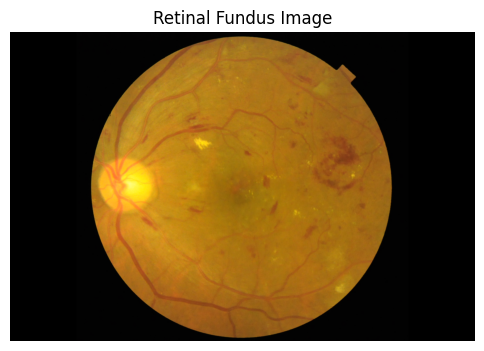

RETINAL DISEASE DIAGNOSIS

RETFound Prediction
-------------------
Diabetic Retinopathy (DR)

Medical Information
-------------------
Diabetic retinopathy is a complication of diabetes that affects blood vessels in the retina, leading to potential vision loss if left untreated. Early detection through regular eye exams can help manage this condition effectively. Symptoms typically do not appear until later stages; however, managing diabetes through lifestyle changes such as physical activity, diet, and medication can significantly reduce the risk of progression to more severe forms like diabetic macular


In [69]:
from PIL import Image
import matplotlib.pyplot as plt

IMAGE_PATH = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/DR/Training_3.png"

# Load image
image = Image.open(IMAGE_PATH).convert("RGB")

# Existing RETFound prediction
predicted_disease = "DR"

# Generate RAG medical information
medical_info = generate_final_rag_explanation(predicted_disease)

# Display final demonstration
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Retinal Fundus Image")
plt.show()

print("=" * 60)
print("RETINAL DISEASE DIAGNOSIS")
print("=" * 60)

print("\nRETFound Prediction")
print("-------------------")
print("Diabetic Retinopathy (DR)")

print("\nMedical Information")
print("-------------------")
print(medical_info)

XAI exists: True


Disease,Confidence
🔴 Diabetic Retinopathy (DR),99.97%

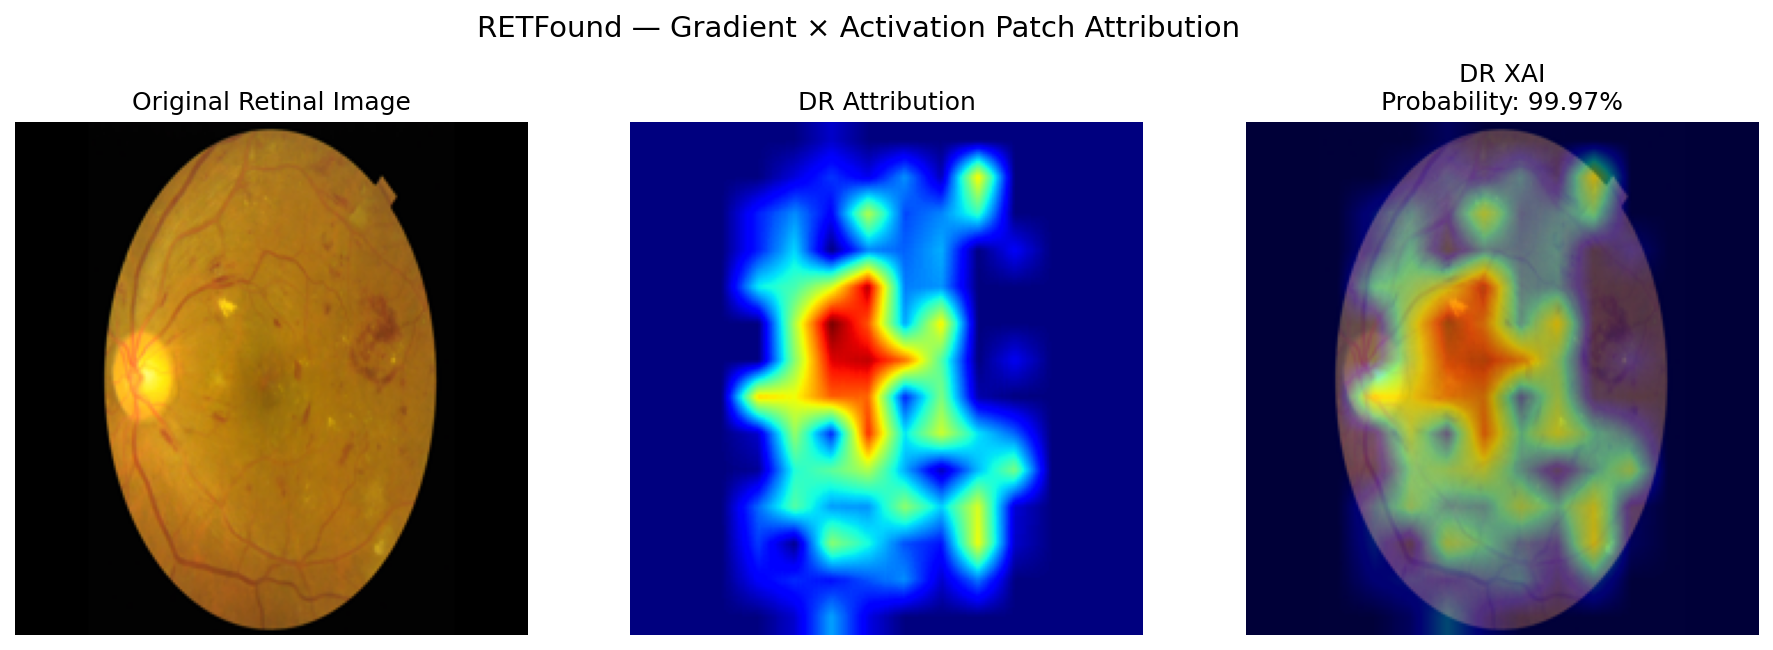

In [71]:
# ============================================================
# FINAL DEMONSTRATION UI
# ============================================================

from PIL import Image
from IPython.display import display, HTML
import os
import base64

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

IMAGE_PATH = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test/DR/Training_3.png"

XAI_VIS_DIR = (
    "/kaggle/input/datasets/rithika2006/"
    "project-phase-1-xai-final-results/"
    "XAI_Results_402_Final/visualizations"
)

# ------------------------------------------------------------
# 2. Existing RETFound result
# ------------------------------------------------------------

demo_image = "Training_3"
predicted_disease = "DR"
disease_name = "Diabetic Retinopathy"

# Actual probability shown by your saved XAI result
confidence = 99.97

# ------------------------------------------------------------
# 3. XAI visualization
# ------------------------------------------------------------

xai_path = os.path.join(
    XAI_VIS_DIR,
    f"{demo_image}_{predicted_disease}_XAI.png"
)

print("XAI exists:", os.path.exists(xai_path))

# ------------------------------------------------------------
# 4. Generate RAG information
# ------------------------------------------------------------

medical_info = generate_final_rag_explanation(
    predicted_disease
).strip()

# Keep complete sentences only
sentences = [
    s.strip()
    for s in medical_info.split(".")
    if s.strip()
]

medical_info = ". ".join(sentences[:2])

if medical_info:
    medical_info += "."

# ------------------------------------------------------------
# 5. Convert XAI image to displayable format
# ------------------------------------------------------------

with open(xai_path, "rb") as f:
    xai_base64 = base64.b64encode(f.read()).decode("utf-8")

# ------------------------------------------------------------
# 6. Final User Interface
# ------------------------------------------------------------

html = f"""
<div style="
    max-width:1100px;
    margin:auto;
    padding:20px;
    border:2px solid #6aa9e9;
    border-radius:15px;
    background:#f7fbff;
    font-family:Arial, sans-serif;
">

<h1 style="
    text-align:center;
    color:#173f70;
    margin-top:0;
">
    RETRIEVAL-AUGMENTED RETINAL DISEASE DIAGNOSIS
</h1>

<div style="
    display:flex;
    gap:20px;
    align-items:stretch;
">

<!-- ===================================================== -->
<!-- LEFT: XAI -->
<!-- ===================================================== -->

<div style="
    width:52%;
    background:white;
    border:1px solid #b8d5f2;
    border-radius:12px;
    padding:15px;
">

<h2 style="
    text-align:center;
    color:#173f70;
">
    Input Fundus Image with XAI
</h2>

<img
    src="data:image/png;base64,{xai_base64}"
    style="
        width:100%;
        border-radius:8px;
    "
>

<p style="
    text-align:center;
    color:#555;
    margin-bottom:0;
">
    XAI visualization showing regions influencing the
    <b>{disease_name}</b> prediction.
</p>

</div>


<!-- ===================================================== -->
<!-- RIGHT -->
<!-- ===================================================== -->

<div style="
    width:48%;
    display:flex;
    flex-direction:column;
    gap:15px;
">

<!-- PREDICTION -->

<div style="
    background:white;
    border:1px solid #b8d5f2;
    border-radius:12px;
    padding:15px;
">

<h2 style="color:#173f70; margin-top:0;">
    Predicted Diseases (Multi-label)
</h2>

<table style="
    width:100%;
    border-collapse:collapse;
    font-size:16px;
">

<tr style="
    background:#eaf4ff;
    color:#173f70;
    font-weight:bold;
">

<th style="padding:10px; text-align:left;">
Disease
</th>

<th style="padding:10px; text-align:right;">
Confidence
</th>

</tr>

<tr>

<td style="padding:12px;">
🔴 {disease_name} ({predicted_disease})
</td>

<td style="
    padding:12px;
    text-align:right;
    font-weight:bold;
">
{confidence:.2f}%
</td>

</tr>

</table>

</div>


<!-- MEDICAL INFORMATION -->

<div style="
    background:white;
    border:1px solid #c8b5f0;
    border-radius:12px;
    padding:15px;
    flex:1;
">

<h2 style="
    color:#4d2b86;
    margin-top:0;
">
    Medical Information
</h2>

<div style="
    background:#eee7ff;
    border-radius:8px;
    padding:10px 14px;
    margin-bottom:12px;
    font-weight:bold;
    color:#3d246e;
">
{disease_name} ({predicted_disease})
</div>

<p style="
    font-size:15px;
    line-height:1.6;
    color:#222;
">
{medical_info}
</p>

</div>

</div>

</div>


<!-- FOOTER -->

<div style="
    margin-top:18px;
    padding:12px;
    background:#e8f3ff;
    border-radius:10px;
    text-align:center;
    color:#173f70;
    font-weight:bold;
">
Prediction + Visual Explanation + Medical Information
</div>

</div>
"""

display(HTML(html))

DR XAI exists: True
TSLN XAI exists: True


Disease,Status
🔴 Diabetic Retinopathy (DR),Predicted
🔴 Tessellation (TSLN),Predicted

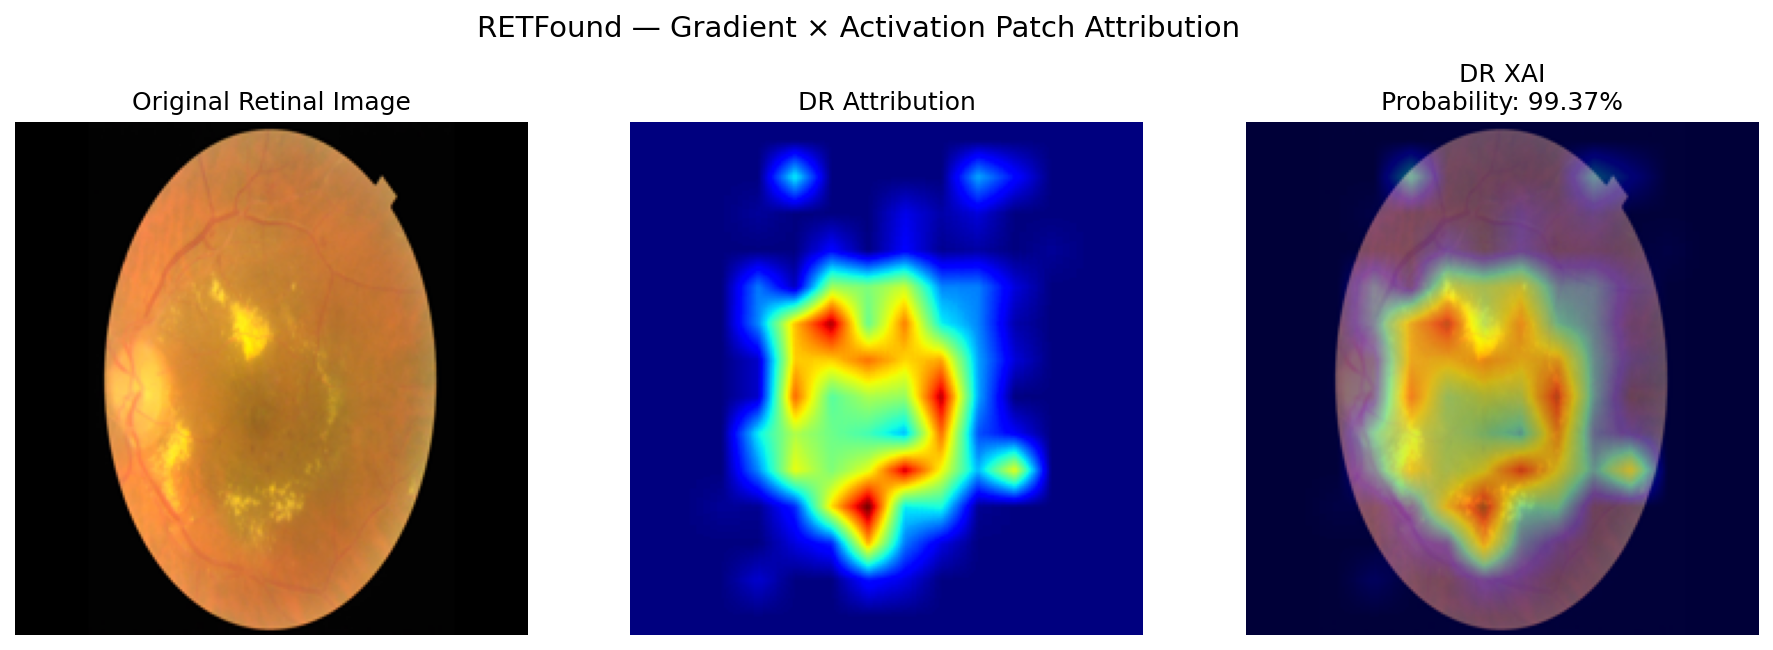
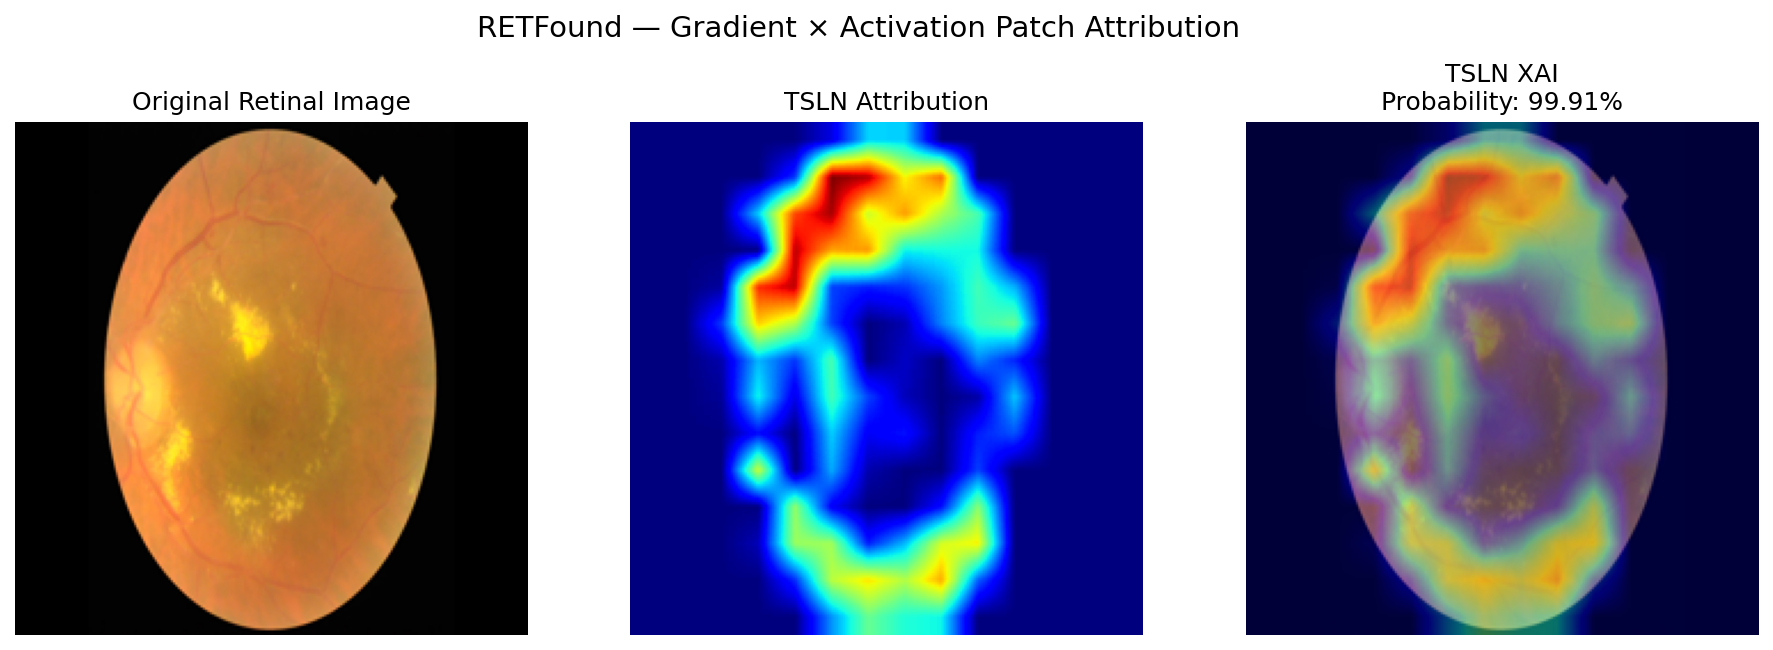

In [74]:
# ============================================================
# FINAL DEMONSTRATION — TWO DISEASE CASE
# Training_11 → MH + ARMD
# ============================================================

from IPython.display import display, HTML
import os
import base64

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

XAI_VIS_DIR = (
    "/kaggle/input/datasets/rithika2006/"
    "project-phase-1-xai-final-results/"
    "XAI_Results_402_Final/visualizations"
)

# ------------------------------------------------------------
# 2. Actual multi-label prediction
# ------------------------------------------------------------

demo_image = "Training_27"

predicted_diseases = ["DR", "TSLN"]

disease_names = {
    "DR": "Diabetic Retinopathy",
    "TSLN": "Tessellation"
}
# ------------------------------------------------------------
# 3. Find XAI visualizations
# ------------------------------------------------------------

xai_paths = {}

for disease in predicted_diseases:

    path = os.path.join(
        XAI_VIS_DIR,
        f"{demo_image}_{disease}_XAI.png"
    )

    xai_paths[disease] = path

    print(f"{disease} XAI exists:", os.path.exists(path))

# ------------------------------------------------------------
# 4. Generate RAG information
# ------------------------------------------------------------

rag_results = {}

for disease in predicted_diseases:

    text_result = generate_final_rag_explanation(disease).strip()

    # Keep first two complete sentences
    sentences = [
        s.strip()
        for s in text_result.split(".")
        if s.strip()
    ]

    clean_text = ". ".join(sentences[:2])

    if clean_text:
        clean_text += "."

    rag_results[disease] = clean_text

# ------------------------------------------------------------
# 5. Convert XAI images to Base64
# ------------------------------------------------------------

xai_base64 = {}

for disease, path in xai_paths.items():

    with open(path, "rb") as f:
        xai_base64[disease] = base64.b64encode(
            f.read()
        ).decode("utf-8")

# ------------------------------------------------------------
# 6. Create VERTICAL XAI section
# ------------------------------------------------------------

xai_panels = ""

for disease in predicted_diseases:

    xai_panels += f"""
    <div style="
        width:100%;
        margin-bottom:25px;
        text-align:center;
    ">

        <h3 style="
            color:#173f70;
            margin:8px 0 12px 0;
            font-size:20px;
        ">
            {disease_names[disease]} ({disease})
        </h3>

        <div style="
            background:#f8fbff;
            border:1px solid #d5e3f2;
            border-radius:10px;
            padding:10px;
        ">

            <img
                src="data:image/png;base64,{xai_base64[disease]}"
                style="
                    width:100%;
                    max-width:520px;
                    height:auto;
                    display:block;
                    margin:auto;
                    border-radius:6px;
                "
            >

        </div>

    </div>
    """

# ------------------------------------------------------------
# 7. Disease prediction table
# ------------------------------------------------------------

disease_rows = ""

for disease in predicted_diseases:

    disease_rows += f"""
    <tr>
        <td style="
            padding:14px;
            font-size:15px;
        ">
            🔴 {disease_names[disease]} ({disease})
        </td>

        <td style="
            padding:14px;
            text-align:center;
            font-weight:bold;
        ">
            Predicted
        </td>
    </tr>
    """

# ------------------------------------------------------------
# 8. RAG information
# ------------------------------------------------------------

rag_html = ""

for disease in predicted_diseases:

    rag_html += f"""
    <div style="
        margin-bottom:18px;
    ">

        <div style="
            background:#eee7ff;
            border-radius:8px;
            padding:11px 14px;
            margin-bottom:8px;
            font-weight:bold;
            color:#3d246e;
        ">
            {disease_names[disease]} ({disease})
        </div>

        <p style="
            font-size:14px;
            line-height:1.6;
            color:#222;
            margin-top:5px;
        ">
            {rag_results[disease]}
        </p>

    </div>
    """

# ------------------------------------------------------------
# 9. FINAL USER INTERFACE
# ------------------------------------------------------------

html = f"""
<div style="
    max-width:1150px;
    margin:auto;
    padding:20px;
    border:2px solid #6aa9e9;
    border-radius:15px;
    background:#f7fbff;
    font-family:Arial,sans-serif;
">

<h1 style="
    text-align:center;
    color:#173f70;
    margin-top:0;
    margin-bottom:20px;
">
    RETRIEVAL-AUGMENTED RETINAL DISEASE DIAGNOSIS
</h1>


<div style="
    display:flex;
    gap:20px;
    align-items:flex-start;
">


<!-- ===================================================== -->
<!-- LEFT : XAI VISUALIZATION -->
<!-- ===================================================== -->

<div style="
    width:55%;
    background:white;
    border:1px solid #b8d5f2;
    border-radius:12px;
    padding:15px;
">

<h2 style="
    text-align:center;
    color:#173f70;
    margin-top:5px;
    margin-bottom:20px;
">
    Visual Explanation (XAI)
</h2>

{xai_panels}

<p style="
    text-align:center;
    color:#555;
    font-size:14px;
    margin-top:5px;
">
    Class-specific XAI visualizations showing the
    retinal regions influencing each predicted disease.
</p>

</div>


<!-- ===================================================== -->
<!-- RIGHT : PREDICTION + RAG -->
<!-- ===================================================== -->

<div style="
    width:45%;
    display:flex;
    flex-direction:column;
    gap:15px;
">


<!-- PREDICTIONS -->

<div style="
    background:white;
    border:1px solid #b8d5f2;
    border-radius:12px;
    padding:15px;
">

<h2 style="
    color:#173f70;
    margin-top:0;
">
    Predicted Diseases (Multi-label)
</h2>

<table style="
    width:100%;
    border-collapse:collapse;
    font-size:15px;
">

<tr style="
    background:#eaf4ff;
    color:#173f70;
    font-weight:bold;
">

<th style="
    padding:10px;
    text-align:left;
">
Disease
</th>

<th style="
    padding:10px;
    text-align:center;
">
Status
</th>

</tr>

{disease_rows}

</table>

</div>


<!-- MEDICAL INFORMATION -->

<div style="
    background:white;
    border:1px solid #c8b5f0;
    border-radius:12px;
    padding:15px;
">

<h2 style="
    color:#4d2b86;
    margin-top:0;
">
    Medical Information
</h2>

{rag_html}

</div>

</div>

</div>


<!-- ===================================================== -->
<!-- FOOTER -->
<!-- ===================================================== -->

<div style="
    margin-top:18px;
    padding:13px;
    background:#e8f3ff;
    border-radius:10px;
    text-align:center;
    color:#173f70;
    font-weight:bold;
">
    Multi-label Prediction + Visual Explanation + Medical Information
</div>

</div>
"""

display(HTML(html))

In [75]:
# ============================================================
# FINAL DEMONSTRATION — IMAGE NAME ONLY
# ============================================================

from IPython.display import display, HTML
import pandas as pd
import os
import base64
import glob
import re

# ============================================================
# 1. USER INPUT
#    ONLY CHANGE THIS IMAGE NAME
# ============================================================

demo_image = "Training_27"


# ============================================================
# 2. PATHS
# ============================================================

XAI_VIS_DIR = (
    "/kaggle/input/datasets/rithika2006/"
    "project-phase-1-xai-final-results/"
    "XAI_Results_402_Final/visualizations"
)

# Search for the saved RETFound prediction/evidence CSV
prediction_csv = None

for root, dirs, files in os.walk("/kaggle/input"):
    if "doctor_facing_retrieval_evidence.csv" in files:
        prediction_csv = os.path.join(
            root,
            "doctor_facing_retrieval_evidence.csv"
        )
        break

if prediction_csv is None:
    raise FileNotFoundError(
        "RETFound prediction CSV was not found."
    )

print("Prediction file:", prediction_csv)


# ============================================================
# 3. LOAD RETFOUND PREDICTIONS
# ============================================================

pred_df = pd.read_csv(prediction_csv)

# Keep one prediction per image
pred_df = pred_df.drop_duplicates(
    subset=["Test_Image_Key"]
).reset_index(drop=True)

# Find the requested image
image_row = pred_df[
    pred_df["Test_Image_Key"].astype(str) == str(demo_image)
]

if image_row.empty:
    raise ValueError(
        f"No RETFound prediction found for {demo_image}"
    )

prediction_text = str(
    image_row.iloc[0]["RETFound_Prediction"]
).strip()

print("RETFound prediction:", prediction_text)


# ============================================================
# 4. EXTRACT PREDICTED DISEASES AUTOMATICALLY
# ============================================================

# Handles formats such as:
# "DR"
# "DR, TSLN"
# "DR, TSLN, ODC"
# "DR; TSLN"

prediction_text = prediction_text.replace(";", ",")

predicted_diseases = [
    x.strip()
    for x in prediction_text.split(",")
    if x.strip()
]

# Remove possible brackets/quotes
predicted_diseases = [
    re.sub(r"[\[\]'\" ]", "", x)
    for x in predicted_diseases
]

print("Predicted classes:", predicted_diseases)


# ============================================================
# 5. DISEASE NAMES
# ============================================================

disease_names = {
    "DR": "Diabetic Retinopathy",
    "MH": "Media Haze",
    "ODC": "Optic Disc Cupping",
    "TSLN": "Tessellation",
    "DN": "Drusen",
    "ARMD": "Age-Related Macular Degeneration",
    "MYA": "Myopia",
    "BRVO": "Branch Retinal Vein Occlusion",
    "ODP": "Optic Disc Pallor",
    "Is_Normal": "Normal"
}


# ============================================================
# 6. FIND XAI VISUALIZATIONS AUTOMATICALLY
# ============================================================

xai_items = []

for disease in predicted_diseases:

    xai_path = os.path.join(
        XAI_VIS_DIR,
        f"{demo_image}_{disease}_XAI.png"
    )

    if os.path.exists(xai_path):
        xai_items.append(
            (disease, xai_path)
        )
    else:
        print(
            f"Warning: XAI visualization not found for {disease}"
        )


# ============================================================
# 7. GENERATE RAG INFORMATION AUTOMATICALLY
# ============================================================

rag_results = {}

for disease in predicted_diseases:

    result = generate_final_rag_explanation(
        disease
    ).strip()

    # Keep first two complete sentences
    sentences = [
        s.strip()
        for s in result.split(".")
        if s.strip()
    ]

    clean_result = ". ".join(
        sentences[:2]
    )

    if clean_result:
        clean_result += "."

    rag_results[disease] = clean_result


# ============================================================
# 8. CONVERT XAI IMAGES TO BASE64
# ============================================================

xai_base64 = {}

for disease, path in xai_items:

    with open(path, "rb") as f:
        xai_base64[disease] = base64.b64encode(
            f.read()
        ).decode("utf-8")


# ============================================================
# 9. BUILD XAI SECTION
# ============================================================

xai_panels = ""

for disease, path in xai_items:

    xai_panels += f"""
    <div style="
        width:100%;
        margin-bottom:25px;
        text-align:center;
    ">

        <h3 style="
            color:#173f70;
            margin:8px 0 12px 0;
            font-size:20px;
        ">
            {disease_names.get(disease, disease)}
            ({disease})
        </h3>

        <div style="
            background:#f8fbff;
            border:1px solid #d5e3f2;
            border-radius:10px;
            padding:10px;
        ">

            <img
                src="data:image/png;base64,
                {xai_base64[disease]}"
                style="
                    width:100%;
                    max-width:520px;
                    height:auto;
                    display:block;
                    margin:auto;
                    border-radius:6px;
                "
            >

        </div>

    </div>
    """


# ============================================================
# 10. BUILD PREDICTION TABLE
# ============================================================

disease_rows = ""

for disease in predicted_diseases:

    disease_rows += f"""
    <tr>

        <td style="
            padding:14px;
            font-size:15px;
        ">
            🔴 {disease_names.get(disease, disease)}
            ({disease})
        </td>

        <td style="
            padding:14px;
            text-align:center;
            font-weight:bold;
        ">
            Predicted
        </td>

    </tr>
    """


# ============================================================
# 11. BUILD RAG SECTION
# ============================================================

rag_html = ""

for disease in predicted_diseases:

    rag_html += f"""
    <div style="
        margin-bottom:18px;
    ">

        <div style="
            background:#eee7ff;
            border-radius:8px;
            padding:11px 14px;
            margin-bottom:8px;
            font-weight:bold;
            color:#3d246e;
        ">
            {disease_names.get(disease, disease)}
            ({disease})
        </div>

        <p style="
            font-size:14px;
            line-height:1.6;
            color:#222;
            margin-top:5px;
        ">
            {rag_results[disease]}
        </p>

    </div>
    """


# ============================================================
# 12. FINAL USER INTERFACE
# ============================================================

html = f"""
<div style="
    max-width:1150px;
    margin:auto;
    padding:20px;
    border:2px solid #6aa9e9;
    border-radius:15px;
    background:#f7fbff;
    font-family:Arial,sans-serif;
">

<h1 style="
    text-align:center;
    color:#173f70;
    margin-top:0;
    margin-bottom:20px;
">
    RETRIEVAL-AUGMENTED RETINAL DISEASE DIAGNOSIS
</h1>


<div style="
    display:flex;
    gap:20px;
    align-items:flex-start;
">


<!-- ====================================================== -->
<!-- LEFT : XAI -->
<!-- ====================================================== -->

<div style="
    width:55%;
    background:white;
    border:1px solid #b8d5f2;
    border-radius:12px;
    padding:15px;
">

<h2 style="
    text-align:center;
    color:#173f70;
    margin-top:5px;
    margin-bottom:20px;
">
    Visual Explanation (XAI)
</h2>

{xai_panels}

<p style="
    text-align:center;
    color:#555;
    font-size:14px;
">
    Class-specific XAI visualizations showing the
    retinal regions influencing each predicted disease.
</p>

</div>


<!-- ====================================================== -->
<!-- RIGHT -->
<!-- ====================================================== -->

<div style="
    width:45%;
    display:flex;
    flex-direction:column;
    gap:15px;
">


<!-- PREDICTION -->

<div style="
    background:white;
    border:1px solid #b8d5f2;
    border-radius:12px;
    padding:15px;
">

<h2 style="
    color:#173f70;
    margin-top:0;
">
    Predicted Diseases (Multi-label)
</h2>

<table style="
    width:100%;
    border-collapse:collapse;
    font-size:15px;
">

<tr style="
    background:#eaf4ff;
    color:#173f70;
    font-weight:bold;
">

<th style="
    padding:10px;
    text-align:left;
">
Disease
</th>

<th style="
    padding:10px;
    text-align:center;
">
Status
</th>

</tr>

{disease_rows}

</table>

</div>


<!-- MEDICAL INFORMATION -->

<div style="
    background:white;
    border:1px solid #c8b5f0;
    border-radius:12px;
    padding:15px;
">

<h2 style="
    color:#4d2b86;
    margin-top:0;
">
    Medical Information
</h2>

{rag_html}

</div>

</div>

</div>


<!-- FOOTER -->

<div style="
    margin-top:18px;
    padding:13px;
    background:#e8f3ff;
    border-radius:10px;
    text-align:center;
    color:#173f70;
    font-weight:bold;
">
    Multi-label Prediction + Visual Explanation + Medical Information
</div>

</div>
"""

display(HTML(html))

Prediction file: /kaggle/input/datasets/rithika2006/project-phase-1-retfound-results/doctor_facing_retrieval_evidence.csv
RETFound prediction: DR, TSLN
Predicted classes: ['DR', 'TSLN']


Disease,Status
🔴 Diabetic Retinopathy (DR),Predicted
🔴 Tessellation (TSLN),Predicted
